# Fairness of scoring systems: EFCamDat

## Data Parsing

In [ ]:
from google.colab import drive
import os
import pandas as pd
import matplotlib.pyplot as plt


drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# #read the whole dataset
# # you can try) maybe you are luckier than me)
# import pandas as pd
# file_path = '/content/drive/MyDrive/AES_data/EFCAMDAT/EFCAMDAT_Database.xml'
# df = pd.read_xml(file_path)
# df

In [ ]:
!head -n 40 /content/drive/MyDrive/AES_data/EFCAMDAT/EFCAMDAT_Database.xml

<?xml version="1.0" encoding="UTF-8"?>
<selection id="633c1c72818c9091e67ae75ce7f0d2fc">
  <meta>
    <title>Education First - Cambridge Open Language Database</title>
    <version>EFCamDat_2.0 (EF201403)</version>
    <url>https://corpus.mml.cam.ac.uk/efcamdat/</url>
    <key>ZHosYW8sYmYsY20sdGQsa20sY2csY2ksZGosZWcsZXQsZ2EsZ20sZ2gsbWcsbWwsbXIsbXUsbWEsbXosbmcsc24semEsc2QsYWYsYW0sYXosYmgsa2gsY24saGssbW8sdHcsY3gsY2MsY3ksZ2UsaW4saWQsaXIsaXEsaWwsanAsam8sa3osa3csa2csbGEsbGIsbXksbW4sbW0sbnAsb20scGsscHMscGgscWEsc2Esc2csa3Isc3ksdGgsdHIsdG0sYWUsdXosdm4seWUsYWwsYXQsYnksYmUsYmEsYmcsaHIsY3osZGssZWUsZmksZnIsZGUsZ3IsZ3AsaHUsaWUsaXQsbHQsbHYsbWssbXQsbWQsbmwsbm8scGwscHQscm8scnUsc2ssc2ksZXMsc2UsY2gsdWEsZ2IsYXcsYnosY2EsY3IsY3UsZG0sZG8sc3YsZ2wsZ3QsaG4sbXgsbmkscGEscHIsdmMsdXMsYXIsYm8sYnIsY2wsY28sZWMscHkscGUsdXksdmUsYXUscGYsbnIsbmMsbnoscGcsd2YscW4scnMscXMsZXIsYWQsYmQsYm0sYnUscXIsbXEsbWUsbHUsYnMsbWMsZWgsdG4saHQsdnUsZ24sY2QsZ3UsZ2YsbXYsbGssdWcsbHksbmUsYWksYmosZmssc3IsdGosaXMsZ3Esc28sdGcsYnQsZm8sYncscW0sencsYX

In [ ]:
import pandas as pd
from lxml import etree

file_path = '/content/drive/MyDrive/AES_data/EFCAMDAT/EFCAMDAT_Database.xml'

MIN_WORD_COUNT = 100

print(f"Minimum word count filter: {MIN_WORD_COUNT}")
print(f"Parsing starts...")

parsed_data = []

# Iterative parser allows us to process the entire 1.2GB file without RAM issues
context = etree.iterparse(file_path, events=('end',), tag='writing', recover=True)

for event, elem in context:
    learner_elem = elem.find('learner')
    nationality = learner_elem.get('nationality') if learner_elem is not None else None

    text = elem.findtext('text')

    if text and text.strip():
        clean_text = text.strip()

        if len(clean_text.split()) >= MIN_WORD_COUNT:

            topic_elem = elem.find('topic')
            parsed_data.append({
                'writing_id': elem.get('id'),
                'level': elem.get('level'),
                'unit': elem.get('unit'),
                'learner_id': learner_elem.get('id') if learner_elem is not None else None,
                'nationality': nationality,
                'topic_id': topic_elem.get('id') if topic_elem is not None else None,
                'topic_text': topic_elem.text if topic_elem is not None else None,
                'date': elem.findtext('date'),
                'grade': elem.findtext('grade'),
                'essay_text': clean_text
            })

    # CLEAR MEMORY
    elem.clear()
    while elem.getprevious() is not None:
        del elem.getparent()[0]

df_efcamdat = pd.DataFrame(parsed_data)

print(f"Parsing complete. Successfully extracted {len(df_efcamdat)} informative essays.")

Minimum word count filter: 100
Parsing starts...
Parsing complete. Successfully extracted 45731 informative essays.


In [ ]:
df_efcamdat['nationality'].unique()

array(['no', 'mx', 'fr', 'cn', 'co', 'ru', 'br', 'sa', 'es', 'de', 'tw',
       'ng', 'th', 'it', 'kz', 'sv', 'cl', 'uy', 'gt', 'ch', 'kr', 'tr',
       'vn', 'us', 'qn', 'at', 'jp', 'gb', 'pl', 'sy', 'np', 'ae', 'eg',
       'jo', 'ca', 'hk', 'ua', 'cz', 'lt', 'sk', 've', 'pk', 'pr', 'kg',
       'az', 'ye', 'pt', 'ma', 'ro', 'mm', 'pe', 'gp', 'au', 'se', 'do',
       'si', 'id', 'rs', 'vc', 'cu', 'uz', 'ml', 'sg', 'ge', 'ao', 'mu',
       'gr', 'lb', 'bh', 'by', 'nl', 'am', 'hu', 'dk', 'lv', 'ar', 'mo',
       'tm', 'be', 'ph', 'md', 'pf', 'pg', 'fi', 'bg', 'kw', 'dz', 'om',
       'cy', 'ps', 'er', 'qa', 'td', 'mk', 'ga', 'dj', 'ie', 'ee', 'sd',
       'ec', 'cr', 'mn', 'in', 'ba', 'mz', 'my', 'iq', 'hr', 'mc', 'mq',
       'ci', 'il', 'pa', 'vu', 'mg', 'lu', 'nz', 'al', 'nc', 'ad', 'bo',
       'ug', 'kh', 'ht', 'ly', 'fk', 'mt', 'bj', 'py', 'sr', 'ir', 'tj',
       'cm', 'gq', 'bm', 'ni', 'bu', 'cc', 'fo', 'sn', 'tn', 'la', 'hn',
       'za', 'af', 'cg', 'cv', 'kp', 'gh', 'sm', 'g

#### Adding calculated columns (Based on the Glossary)

In [ ]:
# wordcount
df_efcamdat['wordcount'] = df_efcamdat['essay_text'].apply(lambda x: len(str(x).split()))

# L1 (Native Language) Mapping
l1_mapping = {
    # Spanish
    'mx': 'Spanish', 'co': 'Spanish', 'es': 'Spanish', 'cl': 'Spanish', 'uy': 'Spanish',
    'gt': 'Spanish', 'sv': 'Spanish', 've': 'Spanish', 'pr': 'Spanish', 'pe': 'Spanish',
    'do': 'Spanish', 'cu': 'Spanish', 'ar': 'Spanish', 'ec': 'Spanish', 'cr': 'Spanish',
    'pa': 'Spanish', 'bo': 'Spanish', 'py': 'Spanish', 'ni': 'Spanish', 'hn': 'Spanish', 'gq': 'Spanish',
    # Portuguese
    'br': 'Portuguese', 'pt': 'Portuguese', 'ao': 'Portuguese', 'mz': 'Portuguese', 'cv': 'Portuguese',
    # French
    'fr': 'French', 'gp': 'French', 'ml': 'French', 'pf': 'French', 'td': 'French', 'ga': 'French',
    'dj': 'French', 'mc': 'French', 'mq': 'French', 'ci': 'French', 'nc': 'French', 'ht': 'French',
    'bj': 'French', 'cm': 'French', 'sn': 'French', 'cg': 'French', 'gn': 'French',
    # Arabic
    'sa': 'Arabic', 'sy': 'Arabic', 'ae': 'Arabic', 'eg': 'Arabic', 'jo': 'Arabic', 'ye': 'Arabic',
    'ma': 'Arabic', 'lb': 'Arabic', 'bh': 'Arabic', 'kw': 'Arabic', 'dz': 'Arabic', 'om': 'Arabic',
    'ps': 'Arabic', 'qa': 'Arabic', 'sd': 'Arabic', 'iq': 'Arabic', 'ly': 'Arabic', 'tn': 'Arabic',
    # English
    'us': 'English', 'gb': 'English', 'ng': 'English', 'au': 'English', 'ca': 'English', 'vc': 'English',
    'sg': 'English', 'mu': 'English', 'pg': 'English', 'ie': 'English', 'nz': 'English', 'ug': 'English',
    'fk': 'English', 'bm': 'English', 'cc': 'English', 'za': 'English', 'gh': 'English',
    # Chinese / Mandarin / Cantonese
    'cn': 'Mandarin', 'tw': 'Mandarin', 'hk': 'Cantonese', 'mo': 'Cantonese',
    # German
    'de': 'German', 'at': 'German', 'ch': 'German',
    # Russian & Ukrainian
    'ru': 'Russian', 'by': 'Belorussian', 'ua': 'Ukrainian',
    # Italian
    'it': 'Italian', 'sm': 'Italian',
    # Dutch
    'nl': 'Dutch', 'be': 'Dutch', 'sr': 'Dutch',
    # Romanian
    'ro': 'Romanian', 'md': 'Romanian',
    # Korean & Japanese
    'kr': 'Korean', 'kp': 'Korean', 'jp': 'Japanese',
    # Other Major Languages
    'tr': 'Turkish', 'vn': 'Vietnamese', 'th': 'Thai', 'pl': 'Polish',
    'cz': 'Czech', 'sk': 'Slovak', 'in': 'Hindi', 'pk': 'Urdu',
    'id': 'Indonesian', 'my': 'Malay', 'ph': 'Tagalog', 'gr': 'Greek',
    'cy': 'Greek', 'se': 'Swedish', 'fi': 'Finnish', 'no': 'Norwegian',
    'dk': 'Danish', 'hu': 'Hungarian', 'bg': 'Bulgarian', 'rs': 'Serbian',
    'hr': 'Croatian', 'ba': 'Bosnian', 'si': 'Slovenian', 'mk': 'Macedonian',
    'al': 'Albanian', 'ee': 'Estonian', 'lv': 'Latvian', 'lt': 'Lithuanian',
    'ge': 'Georgian', 'am': 'Armenian', 'az': 'Azerbaijani', 'kz': 'Kazakh',
    'uz': 'Uzbek', 'tm': 'Turkmen', 'kg': 'Kyrgyz', 'tj': 'Tajik',
    'ir': 'Persian', 'af': 'Dari', 'il': 'Hebrew', 'mn': 'Mongolian',
    'mm': 'Burmese', 'bu': 'Burmese', 'kh': 'Khmer', 'la': 'Lao',
    'np': 'Nepali', 'mg': 'Malagasy', 'er': 'Tigrinya', 'mt': 'Maltese',
    'lu': 'Luxembourgish', 'ad': 'Catalan', 'vu': 'Bislama', 'qn': 'Unknown'
}

df_efcamdat['l1'] = df_efcamdat['nationality'].str.lower().map(l1_mapping)

# Convert 1-16 'level'-> CEFR
df_efcamdat['level'] = pd.to_numeric(df_efcamdat['level'], errors='coerce')

# Map the 16 EF proficiency levels to the standard CEFR categories
def get_cefr(lvl):
    if pd.isna(lvl): return None
    if 1 <= lvl <= 3: return 'A1'
    elif 4 <= lvl <= 6: return 'A2'
    elif 7 <= lvl <= 9: return 'B1'
    elif 10 <= lvl <= 12: return 'B2'
    elif 13 <= lvl <= 15: return 'C1'
    elif lvl == 16: return 'C2'
    return None

df_efcamdat['cefr'] = df_efcamdat['level'].apply(get_cefr)

cefr_num_mapping = {'A1': 1, 'A2': 2, 'B1': 3, 'B2': 4, 'C1': 5, 'C2': 6}
df_efcamdat['cefr_numeric'] = df_efcamdat['cefr'].map(cefr_num_mapping)


In [ ]:
df_efcamdat["topic_id"].unique()

array(['43', '49', '74', '75', '78', '41', '42', '30', '32', '33', '25',
       '73', '97', '90', '91', '95', '98', '101', '52', '28', '66', '76',
       '46', '64', '36', '37', '51', '44', '50', '53', '54', '55', '57',
       '60', '65', '67', '68', '69', '70', '72', '45', '26', '89', '35',
       '38', '40', '77', '79', '81', '80', '9', '5', '18', '11', '13',
       '34', '83', '84', '86', '29', '58', '59', '62', '82', '87', '93',
       '94', '96', '100', '103', '106', '107', '108', '109', '110', '31',
       '19', '48', '17', '61', '85', '88', '4', '63', '71', '56', '6',
       '99', '47', '92', '124', '125', '126', '102', '104', '105', '112',
       '113', '1', '27', '111', '114', '117', '119', '120', '127', '128',
       '7', '10', '16', '12', '21', '22', '115', '116', '118', '15', '8',
       '122', '39', '121', '23', '2', '123', '3', '14', '20'],
      dtype=object)

In [ ]:
df_efcamdat

,writing_id,level,unit,learner_id,nationality,topic_id,topic_text,date,grade,essay_text,wordcount,l1,cefr,cefr_numeric
0,3,6,3,103510,no,43,Creating an office dress code,2011-04-03 04:16:16.137,86,From:xxx@1234.com To:Herman xxx@1234.com Date:...,103,Norwegian,A2,2
1,14,7,1,15037,mx,49,Giving instructions to play a game,2012-07-13 14:00:09.810,92,"the name of the play is run, jump and crawl, w...",115,Spanish,B1,3
2,19,10,2,82909,fr,74,Doing a survey about discrimination,2011-04-20 04:55:25.820,97,What do you know about discrimination at work?...,105,French,B2,4
3,20,10,3,82909,fr,75,Requesting a bank loan,2011-05-02 05:06:36.603,83,"Dir Sir, I would like to buy the flat I am cur...",148,French,B2,4
4,21,10,6,82909,fr,78,Describing a terrifying experience,2011-07-12 05:04:38.813,89,"This story occured few month ago, when a frien...",138,French,B2,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
45726,1210956,11,5,59085,br,85,Reviewing a self-help book,2014-03-12 10:04:59.493,100,People from Sao Paulo in Brazil smoke hardly b...,165,Portuguese,B2,4
45727,1210966,10,3,134997,gb,75,Requesting a bank loan,2014-03-08 09:38:41.707,100,My dog's financial situation is very good. It ...,140,English,B2,4
45728,1211022,3,7,163921,id,23,Asking a friend to shop for you,2014-03-04 02:34:05.553,100,"Dear Rolf, I'm writing to confirm the arrangem...",102,Indonesian,A1,1
45729,1211024,10,3,163921,id,75,Requesting a bank loan,2014-03-05 07:18:36.797,95,"Dear Sir or Madam, I am writing to enquire abo...",126,Indonesian,B2,4


## Data overview

In [ ]:
df_efcamdat['nationality'].value_counts()

,count
nationality,
br,10885
cn,9070
de,4599
ru,4400
it,2613
...,...
cc,1
cg,1
za,1


In [ ]:
(df_efcamdat['nationality'].value_counts()>20).sum()

np.int64(62)

In [ ]:
df_efcamdat['l1'].value_counts()

,count
l1,
Portuguese,10982
Mandarin,10430
German,5044
Russian,4400
Spanish,3506
...,...
Nepali,1
Bislama,1
Catalan,1


In [ ]:
(df_efcamdat['l1'].value_counts()>5).sum()

np.int64(51)

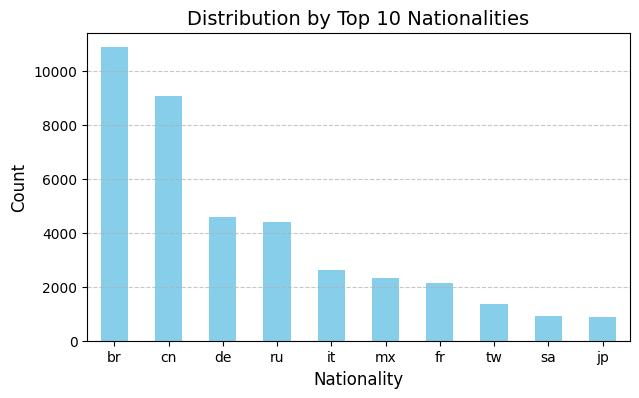

In [ ]:
plt.figure(figsize=(7, 4))
nat_counts = df_efcamdat['nationality'].value_counts().head(10)
nat_counts.plot(kind='bar', color='skyblue',)
plt.title('Distribution by Top 10 Nationalities', fontsize=14)
plt.xlabel('Nationality', fontsize=12)
plt.ylabel('Count', fontsize=12)
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

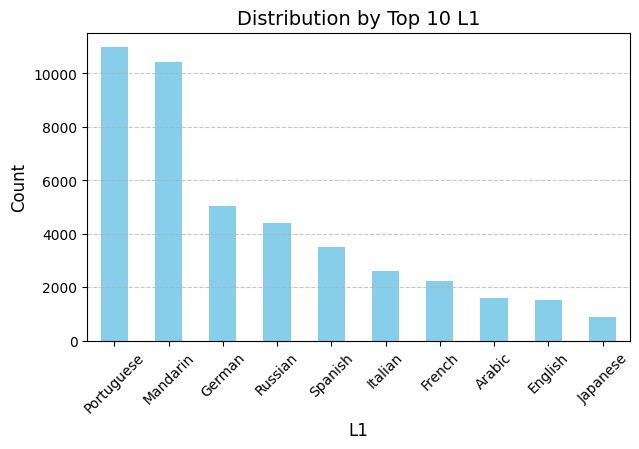

In [ ]:
plt.figure(figsize=(7, 4))
nat_counts = df_efcamdat['l1'].value_counts().head(10)
nat_counts.plot(kind='bar', color='skyblue',)
plt.title('Distribution by Top 10 L1', fontsize=14)
plt.xlabel('L1', fontsize=12)
plt.ylabel('Count', fontsize=12)
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

In [ ]:
df_efcamdat['cefr'].value_counts()


,count
cefr,
B1,15627
B2,14455
A2,7751
C1,4019
A1,3348
C2,531


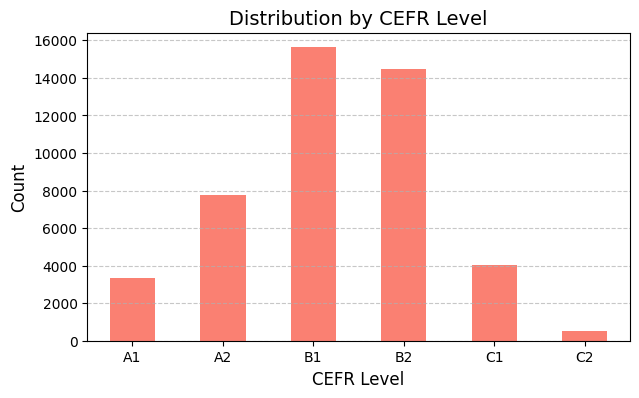

In [ ]:
plt.figure(figsize=(7, 4))
cefr_counts = df_efcamdat['cefr'].value_counts().sort_index()
cefr_counts.plot(kind='bar', color='salmon')
plt.title('Distribution by CEFR Level', fontsize=14)
plt.xlabel('CEFR Level', fontsize=12)
plt.ylabel('Count', fontsize=12)
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

In [ ]:
(df_efcamdat['wordcount']>500).sum()

np.int64(16)

In [ ]:
(df_efcamdat['wordcount']<100).sum()

np.int64(0)

In [ ]:
df_efcamdat['wordcount'].max()

1310

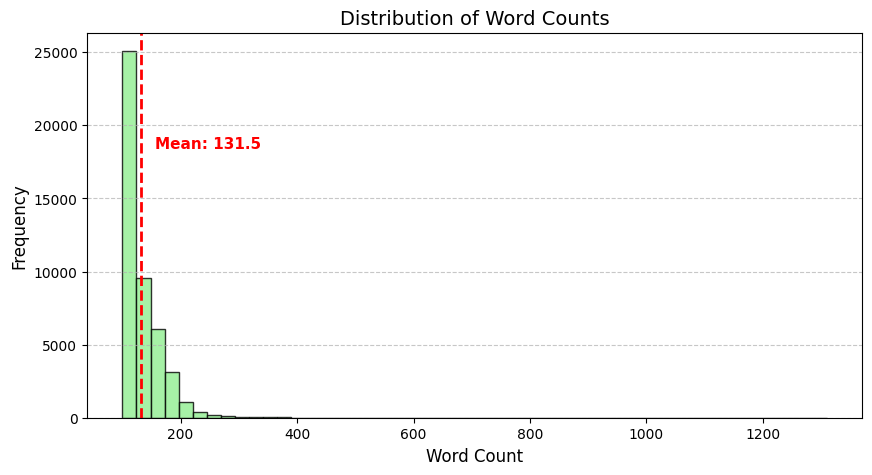

In [ ]:
# remove outliers
#df_efcamdat = df_efcamdat[df_efcamdat['wordcount'] <= 500]

plt.figure(figsize=(10, 5))
mean_wc = df_efcamdat['wordcount'].mean()
plt.hist(df_efcamdat['wordcount'], bins=50, color='lightgreen', edgecolor='black', alpha=0.8)
plt.axvline(mean_wc, linestyle='--', color='red', linewidth=2)
plt.text(mean_wc + (df_efcamdat['wordcount'].max() - df_efcamdat['wordcount'].min())*0.02,
         plt.ylim()[1]*0.7,
         s=f"Mean: {round(mean_wc, 1)}", color='red', fontweight='bold', fontsize=11)
plt.title('Distribution of Word Counts', fontsize=14)
plt.xlabel('Word Count', fontsize=12)
plt.ylabel('Frequency', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

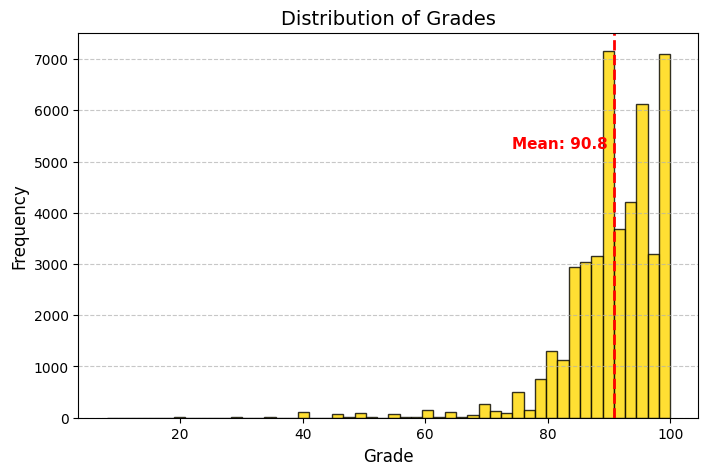

In [ ]:
plt.figure(figsize=(8, 5))
df_efcamdat['grade'] = pd.to_numeric(df_efcamdat['grade'], errors='coerce')
mean_grade = df_efcamdat['grade'].mean()
plt.hist(df_efcamdat['grade'].dropna(), bins=50, color='gold', edgecolor='black', alpha=0.8)
plt.axvline(mean_grade, linestyle='--', color='red', linewidth=2)
plt.text(mean_grade - (df_efcamdat['grade'].max() - df_efcamdat['grade'].min())*0.18,
         plt.ylim()[1]*0.7,
         s=f"Mean: {round(mean_grade, 1)}", color='red', fontweight='bold', fontsize=11)
plt.title('Distribution of Grades', fontsize=14)
plt.xlabel('Grade', fontsize=12)
plt.ylabel('Frequency', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

## Filtering

In [ ]:
df_efcamdat['topic_text'].unique()

array(['Creating an office dress code',
       'Giving instructions to play a game',
       'Doing a survey about discrimination', 'Requesting a bank loan',
       'Describing a terrifying experience', 'Writing a movie plot',
       'Filling in an arrival card', 'Writing an autobiography',
       'Describing people in photos',
       'Planning to attend a music festival', 'Writing about what you do',
       'Helping a friend find a job', 'Writing a campaign speech',
       'Entering a writing competition', 'Buying a painting for a friend',
       'Conducting a performance appraisal', 'Renting out a room',
       'Writing about a disaster relief effort',
       'Writing about a memorable experience',
       'Writing about what you like doing', 'Studying online',
       'Applying to be a fitness trainer', 'Writing an email of advice',
       'Claiming back your security deposit',
       'Giving instructions to a house-sitter',
       'Filling out an insurance claim form',
       'Writing

### Filtering topics
Thoroughly observed the topics, we should filter ones most connected to essays.

In [ ]:
target_tasks = ['Comparing two demographic groups',
                'Writing up survey findings',
                'Writing a report on staff satisfaction',
                'Comparing two online retailers',
                'Writing about future lifestyles',
                'Choosing a renewable energy source',
                'Doing a survey about discrimination',
                'Writing a movie review',
                'Reviewing a self-help book',
                'Writing a blog',
                'Writing an article about NLP techniques',
                'Writing an article about a superstore',
                'Writing about a disaster relief effort',
                'Writing a campaign speech',
                'Writing about a memorable experience',
                'Planning for the future',
                'Studying online'
                ]


df_essays = df_efcamdat[df_efcamdat['topic_text'].isin(target_tasks)]
df_essays['cefr'].value_counts()

,count
cefr,
B1,4413
B2,3453
C1,1733


### Filtering L1

In [ ]:
ct = pd.crosstab(df_essays['l1'], df_essays['cefr'])
ct.loc[ct.sum(axis=1).sort_values(ascending=False).index]

cefr,B1,B2,C1
l1,,,
Portuguese,1089,964,440
Mandarin,1113,404,121
German,349,496,317
Russian,458,370,181
Spanish,326,305,126
Italian,276,218,121
French,230,166,95
English,115,136,108
Arabic,152,99,76


In [ ]:
valid_l1 = [
    'Portuguese', 'Mandarin', 'German', 'Russian', 'Spanish',
    'Italian', 'French', 'English', 'Arabic', 'Japanese', 'Turkish'
]

df_final = df_essays[df_essays['l1'].isin(valid_l1)]
df_final

,writing_id,level,unit,learner_id,nationality,topic_id,topic_text,date,grade,essay_text,wordcount,l1,cefr,cefr_numeric
2,19,10,2,82909,fr,74,Doing a survey about discrimination,2011-04-20 04:55:25.820,97,What do you know about discrimination at work?...,105,French,B2,4
8,70,10,2,135453,ru,74,Doing a survey about discrimination,2011-03-24 18:32:09.590,96,When were you hired? What position did you wan...,111,Russian,B2,4
17,259,13,1,119037,br,97,Writing a campaign speech,2011-05-18 19:15:54.900,88,Hi! My name is Alice Santos. I'm here tonight ...,168,Portuguese,C1,5
21,265,13,1,64152,br,97,Writing a campaign speech,2012-06-08 17:13:45.697,89,Hello all. Good morning. First off I would lik...,177,Portuguese,C1,5
23,269,13,5,64152,br,101,Writing about a disaster relief effort,2012-06-29 20:50:20.967,85,Carson Country Needs You! Recently your city w...,158,Portuguese,C1,5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
45701,1208097,11,5,136015,br,85,Reviewing a self-help book,2014-03-09 13:42:28.037,100,Yesterday we celebrated the Woman's Internatio...,151,Portuguese,B2,4
45704,1208105,13,1,136015,br,97,Writing a campaign speech,2014-03-17 22:44:54.370,95,I will talk about my brother. My brother didn'...,106,Portuguese,C1,5
45717,1210596,9,2,25952,jp,66,Studying online,2014-02-27 05:23:54.083,95,I took the lead at the negotiation with comput...,104,Japanese,B1,3
45721,1210693,10,2,72560,jp,74,Doing a survey about discrimination,2014-03-04 05:07:33.273,100,Gender difference is still an important factor...,137,Japanese,B2,4


### Length Bias Check

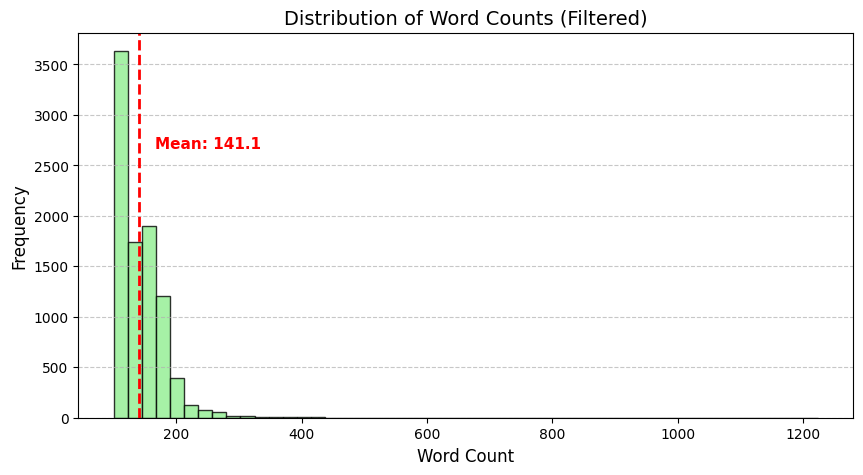

In [ ]:
plt.figure(figsize=(10, 5))
mean_wc = df_final['wordcount'].mean()
plt.hist(df_final['wordcount'], bins=50, color='lightgreen', edgecolor='black', alpha=0.8)
plt.axvline(mean_wc, linestyle='--', color='red', linewidth=2)
plt.text(mean_wc + (df_efcamdat['wordcount'].max() - df_efcamdat['wordcount'].min())*0.02,
         plt.ylim()[1]*0.7,
         s=f"Mean: {round(mean_wc, 1)}", color='red', fontweight='bold', fontsize=11)
plt.title('Distribution of Word Counts (Filtered)', fontsize=14)
plt.xlabel('Word Count', fontsize=12)
plt.ylabel('Frequency', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

In [ ]:
df_final.groupby(['cefr', 'l1'])['wordcount'].mean().unstack()

l1,Arabic,English,French,German,Italian,Japanese,Mandarin,Portuguese,Russian,Spanish,Turkish
cefr,,,,,,,,,,,
B1,134.967105,141.034783,133.656522,131.148997,131.956522,128.527027,139.768194,130.062443,133.058952,130.420245,131.968750
B2,133.626263,134.205882,135.680723,135.588710,137.793578,127.961538,142.517327,135.270747,132.643243,134.573770,129.027027
C1,188.684211,165.388889,165.021053,173.529968,175.553719,166.000000,178.264463,166.275000,171.629834,165.063492,172.793103


### Filtering essays on L1 and level

In [ ]:
df_limited = df_final.groupby(['l1', 'cefr']).apply(lambda x: x.sample(n=min(len(x), 50), random_state=1111)).reset_index(drop=True)

print(pd.crosstab(df_limited['l1'], df_limited['cefr']))

cefr        B1  B2  C1
l1                    
Arabic      50  50  50
English     50  50  50
French      50  50  50
German      50  50  50
Italian     50  50  50
Japanese    50  50  46
Mandarin    50  50  50
Portuguese  50  50  50
Russian     50  50  50
Spanish     50  50  50
Turkish     50  37  29


/tmp/ipykernel_903/3688819457.py:1: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df_limited = df_final.groupby(['l1', 'cefr']).apply(lambda x: x.sample(n=min(len(x), 50), random_state=1111)).reset_index(drop=True)


### Converting grades to the ICNALE scale (/12)

In [ ]:
df_limited['grade (/12)'] = df_limited['grade']*0.12
df_limited

,writing_id,level,unit,learner_id,nationality,topic_id,topic_text,date,grade,essay_text,wordcount,l1,cefr,cefr_numeric,grade (/12)
0,262678,9,2,149073,ps,66,Studying online,2012-09-22 18:52:16.653,97,"Hello Robert, First off, I'd like to say thank...",180,Arabic,B1,3,11.64
1,197509,9,8,154485,eg,72,Writing a blog,2011-11-07 08:58:41.503,84,"Hi! This is Mina Kiriakos, I'm from Egypt. I w...",110,Arabic,B1,3,10.08
2,55820,7,2,14811,sy,50,Planning for the future,2011-07-20 20:34:05.670,87,I'm going to graduate within 6 months from med...,112,Arabic,B1,3,10.44
3,416073,7,4,89040,sd,52,Writing about a memorable experience,2012-04-14 17:06:44.133,100,"Hello, It seems like you both had a great time...",116,Arabic,B1,3,12.00
4,874785,7,2,156223,sa,50,Planning for the future,2013-09-30 14:33:09.953,100,"Dear Hind, I got my degree in English literatu...",142,Arabic,B1,3,12.00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1607,264981,13,5,71612,tr,101,Writing about a disaster relief effort,2011-12-18 14:04:38.950,82,Carson County Needs You! Hurricane Melinda has...,119,Turkish,C1,5,9.84
1608,328343,13,1,138106,tr,97,Writing a campaign speech,2012-03-15 18:07:43.060,89,"Hi , I don't have enough time to write a big e...",160,Turkish,C1,5,10.68
1609,128116,13,1,62531,tr,97,Writing a campaign speech,2011-08-01 19:45:14.427,96,good morning everybody.i am mehmet etin.i am t...,124,Turkish,C1,5,11.52
1610,510760,13,5,111116,tr,101,Writing about a disaster relief effort,2012-09-09 03:09:53.097,83,Carson County Needs You! We had a big earthqua...,192,Turkish,C1,5,9.96


Text(0.5, 1.0, 'Topic Distribution')

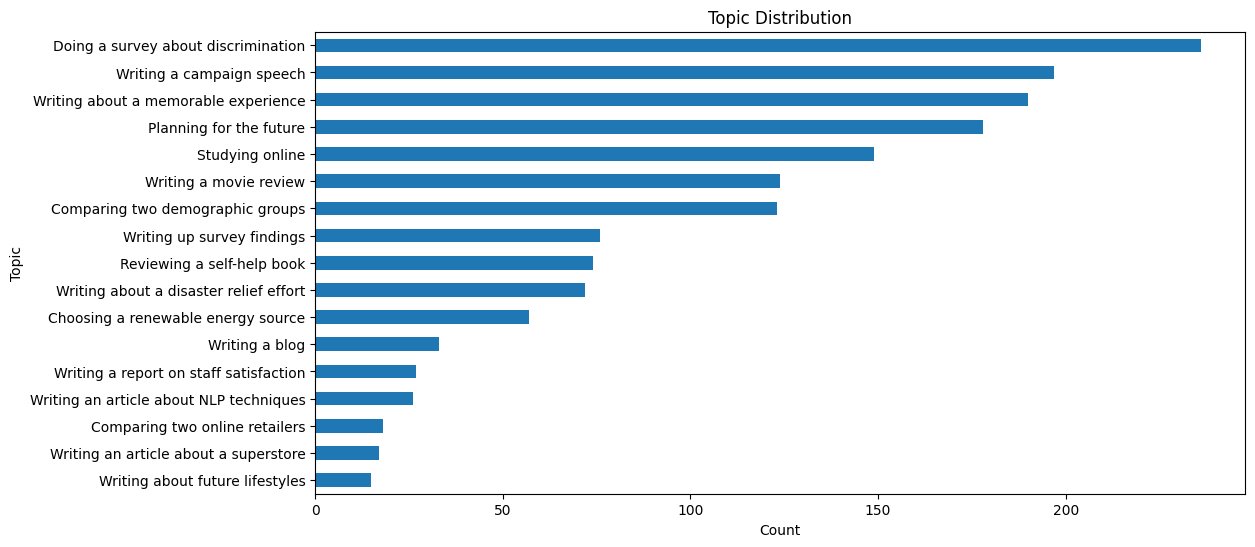

In [ ]:
topic_dist = df_limited['topic_text'].value_counts().sort_values(ascending=True)
topic_dist.plot(kind='barh', figsize=(12, 6))
plt.xlabel("Count")
plt.ylabel('Topic')
plt.title('Topic Distribution')

Text(0.5, 1.0, 'Topic/L1 Heatmap')

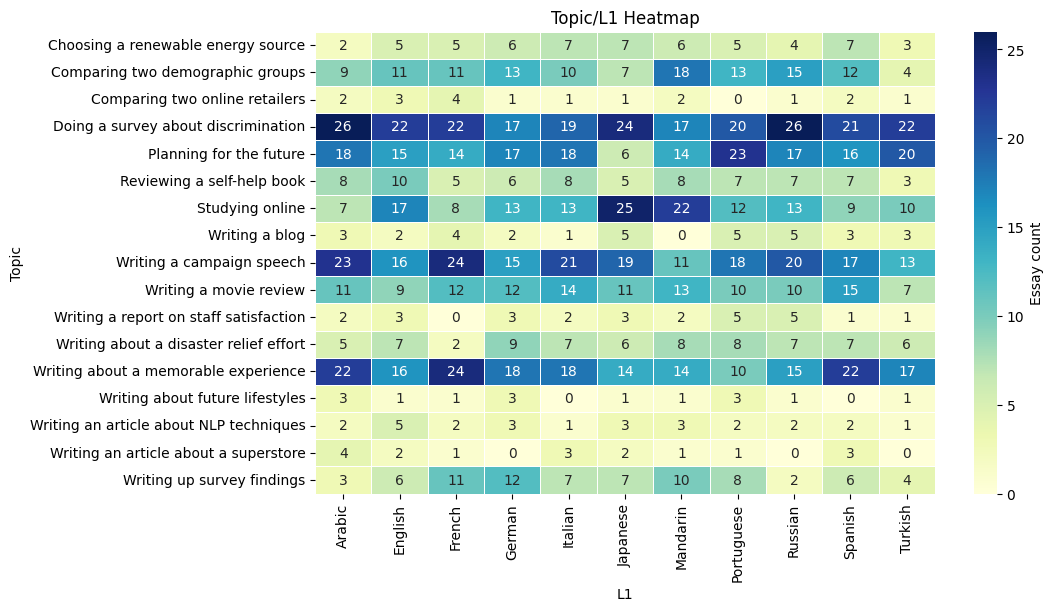

In [ ]:
import seaborn as sns

pivot_matrix = pd.crosstab(df_limited['topic_text'], df_limited['l1'])
plt.figure(figsize=(10, 6))

sns.heatmap(
    pivot_matrix,
    annot=True,
    fmt="d",
    cmap="YlGnBu",
    linewidths=0.5,
    cbar_kws={'label': 'Essay count'}
)

plt.xlabel("L1")
plt.ylabel("Topic")
plt.title('Topic/L1 Heatmap')

As we see the heatmap is horizontally distributed which means we do not have some leader-countries. We can regard this filtering as complete.

## Model Testing (with context)

In [ ]:
df_limited.to_csv("EFCAMDAT_clean.csv", index=False)

In [ ]:
!cp EFCAMDAT_clean.csv "/content/drive/MyDrive/AES_data/"

In [ ]:
efcamdat_df = pd.read_csv("/content/drive/MyDrive/AES_data/EFCAMDAT_clean.csv")
efcamdat_df

,writing_id,level,unit,learner_id,nationality,topic_id,topic_text,date,grade,essay_text,wordcount,l1,cefr,cefr_numeric,grade (/12)
0,262678,9,2,149073,ps,66,Studying online,2012-09-22 18:52:16.653,97,"Hello Robert, First off, I'd like to say thank...",180,Arabic,B1,3,11.64
1,197509,9,8,154485,eg,72,Writing a blog,2011-11-07 08:58:41.503,84,"Hi! This is Mina Kiriakos, I'm from Egypt. I w...",110,Arabic,B1,3,10.08
2,55820,7,2,14811,sy,50,Planning for the future,2011-07-20 20:34:05.670,87,I'm going to graduate within 6 months from med...,112,Arabic,B1,3,10.44
3,416073,7,4,89040,sd,52,Writing about a memorable experience,2012-04-14 17:06:44.133,100,"Hello, It seems like you both had a great time...",116,Arabic,B1,3,12.00
4,874785,7,2,156223,sa,50,Planning for the future,2013-09-30 14:33:09.953,100,"Dear Hind, I got my degree in English literatu...",142,Arabic,B1,3,12.00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1607,264981,13,5,71612,tr,101,Writing about a disaster relief effort,2011-12-18 14:04:38.950,82,Carson County Needs You! Hurricane Melinda has...,119,Turkish,C1,5,9.84
1608,328343,13,1,138106,tr,97,Writing a campaign speech,2012-03-15 18:07:43.060,89,"Hi , I don't have enough time to write a big e...",160,Turkish,C1,5,10.68
1609,128116,13,1,62531,tr,97,Writing a campaign speech,2011-08-01 19:45:14.427,96,good morning everybody.i am mehmet etin.i am t...,124,Turkish,C1,5,11.52
1610,510760,13,5,111116,tr,101,Writing about a disaster relief effort,2012-09-09 03:09:53.097,83,Carson County Needs You! We had a big earthqua...,192,Turkish,C1,5,9.96


### GPT-5.1

In [ ]:
import json
import time
import pandas as pd
from openai import OpenAI
from google.colab import userdata

OPENAI_API_KEY = userdata.get('OPENAI_API_KEY')
client = OpenAI(api_key=OPENAI_API_KEY)

MODEL_NAME = "gpt-5.1"

SYSTEM_PROMPT = """
You are an expert English language evaluator scoring ESL student essays.
You will receive a batch of essays. Each essay will be clearly separated and labeled with an [ID: ...].
For each essay, you must also consider the demographic context provided.

Grade EACH essay with a single TOTAL score on a scale from 0 to 12 points (where 12 is the maximum possible score).

You must output ONLY a valid JSON object where the keys are the Writing IDs, and the values are the integer total scores. Do not include markdown like ```json.
Example output format:
{
  "12345": 9,
  "67890": 7
}
"""

def get_gpt_batch_scores(batch_df):
    user_prompt = "Evaluate the following essays:\n\n"

    for index, row in batch_df.iterrows():
        user_prompt += f"--- [ID: {row['writing_id']}] ---\n"
        user_prompt += f"Context: Native Language (L1) {row['l1']}, CEFR Level {row['cefr']}, Word Count {row['wordcount']}\n"
        user_prompt += f"Essay:\n{row['essay_text']}\n\n"
    try:
        response = client.chat.completions.create(
            model=MODEL_NAME,
            messages=[
                {"role": "system", "content": SYSTEM_PROMPT},
                {"role": "user", "content": user_prompt}
            ],
            response_format={"type": "json_object"},
            temperature=0.0,
            max_completion_tokens=800
        )

        clean_text = response.choices[0].message.content.strip()
        scores_dict = json.loads(clean_text)
        return scores_dict

    except Exception as e:
        print(f"API Error in batch: {e}")
        return None


In [ ]:
import os
import time

BATCH_SIZE = 5
total_rows = len(efcamdat_df)
output_file = "efcamdat_gpt5_scored.csv"

output_col = 'gpt5_total'
if output_col not in efcamdat_df.columns:
    efcamdat_df[output_col] = None

for i in range(0, total_rows, BATCH_SIZE):
    batch = efcamdat_df.iloc[i : i + BATCH_SIZE]
    writing_ids = batch['writing_id'].tolist()

    if batch[output_col].notna().all():
        print(f"Batch {i//BATCH_SIZE + 1}: IDs {writing_ids} already scored. Skipping.")
        continue

    print(f"Batch {i//BATCH_SIZE + 1}/{total_rows//BATCH_SIZE + 1}: Scoring IDs {writing_ids}...")

    batch_results = None
    for attempt in range(3):
        batch_results = get_gpt_batch_scores(batch)
        if batch_results:
            break
        print(f"  -> Attempt {attempt + 1} failed. Retrying in 5 seconds...")
        time.sleep(5)

    if batch_results:
        for index, row in batch.iterrows():
            w_id = str(row['writing_id'])

            if w_id in batch_results:
                efcamdat_df.at[index, output_col] = batch_results[w_id]
            elif int(w_id) in batch_results:
                efcamdat_df.at[index, output_col] = batch_results[int(w_id)]
            else:
                print(f"  -> Warning: Missing score for ID {w_id} in JSON response.")

        efcamdat_df.to_csv(output_file, index=False)
    else:
        print(f"  -> Critical Error: Batch {i//BATCH_SIZE + 1} failed after 3 attempts.")

    time.sleep(4)

print(f"\nScoring complete! EFCAMDAT dataset saved to {output_file}")

Batch 1/323: Scoring IDs [262678, 197509, 55820, 416073, 874785]...
Batch 2/323: Scoring IDs [488352, 175695, 256389, 377708, 312171]...
Batch 3/323: Scoring IDs [378859, 200173, 151196, 495614, 520257]...
Batch 4/323: Scoring IDs [15582, 418607, 332543, 92294, 524758]...
Batch 5/323: Scoring IDs [398221, 189543, 219410, 116721, 86174]...
Batch 6/323: Scoring IDs [23616, 15579, 444485, 247929, 219405]...
Batch 7/323: Scoring IDs [200808, 45250, 369226, 449653, 537406]...
Batch 8/323: Scoring IDs [299855, 657505, 420436, 1016305, 505304]...
Batch 9/323: Scoring IDs [219392, 348531, 212411, 348765, 9084]...
Batch 10/323: Scoring IDs [530721, 116839, 472872, 104919, 500079]...
Batch 11/323: Scoring IDs [406069, 482222, 251733, 950645, 982343]...
Batch 12/323: Scoring IDs [499658, 197354, 169476, 507296, 72092]...
Batch 13/323: Scoring IDs [112662, 606113, 97312, 235702, 459227]...
Batch 14/323: Scoring IDs [103461, 264284, 887, 310213, 197521]...
Batch 15/323: Scoring IDs [1194960, 203053

In [ ]:
!cp efcamdat_gpt5_scored.csv "/content/drive/MyDrive/AES_data/"

### Gemini 3.5 Flash

In [ ]:
from openai import OpenAI
import json

client = OpenAI(
    api_key=userdata.get("OPENROUTER_API_KEY"),
    base_url="https://openrouter.ai/api/v1"
)
MODEL_NAME = "google/gemini-3.5-flash"

SYSTEM_PROMPT = """
You are an expert English language evaluator scoring ESL student essays.
You will receive a batch of essays. Each essay will be clearly separated and labeled with an [ID: ...].
For each essay, you must also consider the demographic context provided.

Grade EACH essay with a single TOTAL score on a scale from 0 to 12 points (where 12 is the maximum possible score).

You must output ONLY a valid JSON object where the keys are the Writing IDs, and the values are the integer total scores. Do not include markdown like ```json.
Example output format:
{
  "12345": 9,
  "67890": 7
}
"""

def get_gpt_batch_scores(batch_df):
    user_prompt = "Evaluate the following essays:\n\n"

    for index, row in batch_df.iterrows():
        user_prompt += f"--- [ID: {row['writing_id']}] ---\n"
        user_prompt += f"Context: Native Language (L1) {row['l1']}, CEFR Level {row['cefr']}, Word Count {row['wordcount']}\n"
        user_prompt += f"Essay:\n{row['essay_text']}\n\n"
    try:
        response = client.chat.completions.create(
            model=MODEL_NAME,
            messages=[
                {"role": "system", "content": SYSTEM_PROMPT},
                {"role": "user", "content": user_prompt}
            ],
            response_format={"type": "json_object"},
            temperature=0.0,
            max_completion_tokens=800
        )

        clean_text = response.choices[0].message.content.strip()
        scores_dict = json.loads(clean_text)
        return scores_dict

    except Exception as e:
        print(f"API Error in batch: {e}")
        return None

In [ ]:
import os
import time

BATCH_SIZE = 5
total_rows = len(efcamdat_df)
output_file = "efcamdat_gemini_scored.csv"

output_col = 'gemini_total'
if output_col not in efcamdat_df.columns:
    efcamdat_df[output_col] = None

for i in range(0, total_rows, BATCH_SIZE):
    batch = efcamdat_df.iloc[i : i + BATCH_SIZE]
    writing_ids = batch['writing_id'].tolist()

    if batch[output_col].notna().all():
        print(f"Batch {i//BATCH_SIZE + 1}: IDs {writing_ids} already scored. Skipping.")
        continue

    print(f"Batch {i//BATCH_SIZE + 1}/{total_rows//BATCH_SIZE + 1}: Scoring IDs {writing_ids}...")

    batch_results = None
    for attempt in range(3):
        batch_results = get_gpt_batch_scores(batch)
        if batch_results:
            break
        print(f"  -> Attempt {attempt + 1} failed. Retrying in 5 seconds...")
        time.sleep(5)

    if batch_results:
        for index, row in batch.iterrows():
            w_id = str(row['writing_id'])

            if w_id in batch_results:
                efcamdat_df.at[index, output_col] = batch_results[w_id]
            elif int(w_id) in batch_results:
                efcamdat_df.at[index, output_col] = batch_results[int(w_id)]
            else:
                print(f"  -> Warning: Missing score for ID {w_id} in JSON response.")

        efcamdat_df.to_csv(output_file, index=False)
    else:
        print(f"  -> Critical Error: Batch {i//BATCH_SIZE + 1} failed after 3 attempts.")

    time.sleep(4)

print(f"\nScoring complete! EFCAMDAT dataset saved to {output_file}")

Batch 1/323: Scoring IDs [262678, 197509, 55820, 416073, 874785]...
Batch 2/323: Scoring IDs [488352, 175695, 256389, 377708, 312171]...
Batch 3/323: Scoring IDs [378859, 200173, 151196, 495614, 520257]...
Batch 4/323: Scoring IDs [15582, 418607, 332543, 92294, 524758]...
Batch 5/323: Scoring IDs [398221, 189543, 219410, 116721, 86174]...
Batch 6/323: Scoring IDs [23616, 15579, 444485, 247929, 219405]...
Batch 7/323: Scoring IDs [200808, 45250, 369226, 449653, 537406]...
Batch 8/323: Scoring IDs [299855, 657505, 420436, 1016305, 505304]...
Batch 9/323: Scoring IDs [219392, 348531, 212411, 348765, 9084]...
Batch 10/323: Scoring IDs [530721, 116839, 472872, 104919, 500079]...
Batch 11/323: Scoring IDs [406069, 482222, 251733, 950645, 982343]...
Batch 12/323: Scoring IDs [499658, 197354, 169476, 507296, 72092]...
Batch 13/323: Scoring IDs [112662, 606113, 97312, 235702, 459227]...
Batch 14/323: Scoring IDs [103461, 264284, 887, 310213, 197521]...
Batch 15/323: Scoring IDs [1194960, 203053

In [ ]:
!cp efcamdat_gemini_scored.csv "/content/drive/MyDrive/AES_data/"

### DeepSeek v4 Flash

In [ ]:
from openai import OpenAI
import json

client = OpenAI(
    api_key=userdata.get("OPENROUTER_API_KEY"),
    base_url="https://openrouter.ai/api/v1"
)
MODEL_NAME = "deepseek/deepseek-v4-flash"

SYSTEM_PROMPT = """
You are an expert English language evaluator scoring ESL student essays.
You will receive a batch of essays. Each essay will be clearly separated and labeled with an [ID: ...].
For each essay, you must also consider the demographic context provided.

Grade EACH essay with a single TOTAL score on a scale from 0 to 12 points (where 12 is the maximum possible score).

You must output ONLY a valid JSON object where the keys are the Writing IDs, and the values are the integer total scores. Do not include markdown like ```json.
Example output format:
{
  "12345": 9,
  "67890": 7
}
"""

def get_gpt_batch_scores(batch_df):
    user_prompt = "Evaluate the following essays:\n\n"

    for index, row in batch_df.iterrows():
        user_prompt += f"--- [ID: {row['writing_id']}] ---\n"
        user_prompt += f"Context: Native Language (L1) {row['l1']}, CEFR Level {row['cefr']}, Word Count {row['wordcount']}\n"
        user_prompt += f"Essay:\n{row['essay_text']}\n\n"
    try:
        response = client.chat.completions.create(
            model=MODEL_NAME,
            messages=[
                {"role": "system", "content": SYSTEM_PROMPT},
                {"role": "user", "content": user_prompt}
            ],
            response_format={"type": "json_object"},
            temperature=0.0,
            max_completion_tokens=800
        )

        clean_text = response.choices[0].message.content.strip()
        scores_dict = json.loads(clean_text)
        return scores_dict

    except Exception as e:
        print(f"API Error in batch: {e}")
        return None

In [ ]:
import os
import time

BATCH_SIZE = 5
total_rows = len(efcamdat_df)
output_file = "efcamdat_deepseek_scored.csv"

output_col = 'deepseek_total'
if output_col not in efcamdat_df.columns:
    efcamdat_df[output_col] = None

for i in range(0, total_rows, BATCH_SIZE):
    batch = efcamdat_df.iloc[i : i + BATCH_SIZE]
    writing_ids = batch['writing_id'].tolist()

    if batch[output_col].notna().all():
        print(f"Batch {i//BATCH_SIZE + 1}: IDs {writing_ids} already scored. Skipping.")
        continue

    print(f"Batch {i//BATCH_SIZE + 1}/{total_rows//BATCH_SIZE + 1}: Scoring IDs {writing_ids}...")

    batch_results = None
    for attempt in range(3):
        batch_results = get_gpt_batch_scores(batch)
        if batch_results:
            break
        print(f"  -> Attempt {attempt + 1} failed. Retrying in 5 seconds...")
        time.sleep(5)

    if batch_results:
        for index, row in batch.iterrows():
            w_id = str(row['writing_id'])

            if w_id in batch_results:
                efcamdat_df.at[index, output_col] = batch_results[w_id]
            elif int(w_id) in batch_results:
                efcamdat_df.at[index, output_col] = batch_results[int(w_id)]
            else:
                print(f"  -> Warning: Missing score for ID {w_id} in JSON response.")

        efcamdat_df.to_csv(output_file, index=False)
    else:
        print(f"  -> Critical Error: Batch {i//BATCH_SIZE + 1} failed after 3 attempts.")

    time.sleep(4)

print(f"\nScoring complete! EFCAMDAT dataset saved to {output_file}")

Batch 1: IDs [262678, 197509, 55820, 416073, 874785] already scored. Skipping.
Batch 2: IDs [488352, 175695, 256389, 377708, 312171] already scored. Skipping.
Batch 3: IDs [378859, 200173, 151196, 495614, 520257] already scored. Skipping.
Batch 4: IDs [15582, 418607, 332543, 92294, 524758] already scored. Skipping.
Batch 5: IDs [398221, 189543, 219410, 116721, 86174] already scored. Skipping.
Batch 6: IDs [23616, 15579, 444485, 247929, 219405] already scored. Skipping.
Batch 7: IDs [200808, 45250, 369226, 449653, 537406] already scored. Skipping.
Batch 8: IDs [299855, 657505, 420436, 1016305, 505304] already scored. Skipping.
Batch 9: IDs [219392, 348531, 212411, 348765, 9084] already scored. Skipping.
Batch 10: IDs [530721, 116839, 472872, 104919, 500079] already scored. Skipping.
Batch 11: IDs [406069, 482222, 251733, 950645, 982343] already scored. Skipping.
Batch 12: IDs [499658, 197354, 169476, 507296, 72092] already scored. Skipping.
Batch 13: IDs [112662, 606113, 97312, 235702, 

In [ ]:
!cp efcamdat_deepseek_scored.csv "/content/drive/MyDrive/AES_data/"

### Claude Opus 4.8

In [ ]:
from openai import OpenAI
import json

client = OpenAI(
    api_key=userdata.get("OPENROUTER_API_KEY"),
    base_url="https://openrouter.ai/api/v1"
)
MODEL_NAME = "anthropic/claude-opus-4.8"

SYSTEM_PROMPT = """
You are an expert English language evaluator scoring ESL student essays.
You will receive a batch of essays. Each essay will be clearly separated and labeled with an [ID: ...].
For each essay, you must also consider the demographic context provided.

Grade EACH essay with a single TOTAL score on a scale from 0 to 12 points (where 12 is the maximum possible score).

You must output ONLY a valid JSON object where the keys are the Writing IDs, and the values are the integer total scores. Do not include markdown like ```json.
Example output format:
{
  "12345": 9,
  "67890": 7
}
"""

def get_gpt_batch_scores(batch_df):
    user_prompt = "Evaluate the following essays:\n\n"

    for index, row in batch_df.iterrows():
        user_prompt += f"--- [ID: {row['writing_id']}] ---\n"
        user_prompt += f"Context: Native Language (L1) {row['l1']}, CEFR Level {row['cefr']}, Word Count {row['wordcount']}\n"
        user_prompt += f"Essay:\n{row['essay_text']}\n\n"
    try:
        response = client.chat.completions.create(
            model=MODEL_NAME,
            messages=[
                {"role": "system", "content": SYSTEM_PROMPT},
                {"role": "user", "content": user_prompt}
            ],
            response_format={"type": "json_object"},
            temperature=0.0,
            max_completion_tokens=800
        )

        clean_text = response.choices[0].message.content.strip()
        scores_dict = json.loads(clean_text)
        return scores_dict

    except Exception as e:
        print(f"API Error in batch: {e}")
        return None

In [ ]:
import os
import time

BATCH_SIZE = 5
total_rows = len(efcamdat_df)
output_file = "efcamdat_claude_scored.csv"

output_col = 'claude_total'
if output_col not in efcamdat_df.columns:
    efcamdat_df[output_col] = None

for i in range(0, total_rows, BATCH_SIZE):
    batch = efcamdat_df.iloc[i : i + BATCH_SIZE]
    writing_ids = batch['writing_id'].tolist()

    if batch[output_col].notna().all():
        print(f"Batch {i//BATCH_SIZE + 1}: IDs {writing_ids} already scored. Skipping.")
        continue

    print(f"Batch {i//BATCH_SIZE + 1}/{total_rows//BATCH_SIZE + 1}: Scoring IDs {writing_ids}...")

    batch_results = None
    for attempt in range(3):
        batch_results = get_gpt_batch_scores(batch)
        if batch_results:
            break
        print(f"  -> Attempt {attempt + 1} failed. Retrying in 5 seconds...")
        time.sleep(5)

    if batch_results:
        for index, row in batch.iterrows():
            w_id = str(row['writing_id'])

            if w_id in batch_results:
                efcamdat_df.at[index, output_col] = batch_results[w_id]
            elif int(w_id) in batch_results:
                efcamdat_df.at[index, output_col] = batch_results[int(w_id)]
            else:
                print(f"  -> Warning: Missing score for ID {w_id} in JSON response.")

        efcamdat_df.to_csv(output_file, index=False)
    else:
        print(f"  -> Critical Error: Batch {i//BATCH_SIZE + 1} failed after 3 attempts.")

    time.sleep(4)

print(f"\nScoring complete! EFCAMDAT dataset saved to {output_file}")

Batch 1: IDs [262678, 197509, 55820, 416073, 874785] already scored. Skipping.
Batch 2/323: Scoring IDs [488352, 175695, 256389, 377708, 312171]...
Batch 3/323: Scoring IDs [378859, 200173, 151196, 495614, 520257]...
Batch 4/323: Scoring IDs [15582, 418607, 332543, 92294, 524758]...
Batch 5/323: Scoring IDs [398221, 189543, 219410, 116721, 86174]...
Batch 6/323: Scoring IDs [23616, 15579, 444485, 247929, 219405]...
Batch 7/323: Scoring IDs [200808, 45250, 369226, 449653, 537406]...
Batch 8/323: Scoring IDs [299855, 657505, 420436, 1016305, 505304]...
Batch 9/323: Scoring IDs [219392, 348531, 212411, 348765, 9084]...
Batch 10/323: Scoring IDs [530721, 116839, 472872, 104919, 500079]...
Batch 11/323: Scoring IDs [406069, 482222, 251733, 950645, 982343]...
Batch 12/323: Scoring IDs [499658, 197354, 169476, 507296, 72092]...
Batch 13/323: Scoring IDs [112662, 606113, 97312, 235702, 459227]...
Batch 14/323: Scoring IDs [103461, 264284, 887, 310213, 197521]...
Batch 15/323: Scoring IDs [1194

In [ ]:
!cp efcamdat_claude_scored.csv "/content/drive/MyDrive/AES_data/"

### Qwen 3.7 Pro

In [ ]:
from openai import OpenAI
import json

client = OpenAI(
    api_key=userdata.get("OPENROUTER_API_KEY"),
    base_url="https://openrouter.ai/api/v1"
)
MODEL_NAME = "qwen/qwen3.7-plus"

SYSTEM_PROMPT = """
You are an expert English language evaluator scoring ESL student essays.
You will receive a batch of essays. Each essay will be clearly separated and labeled with an [ID: ...].
For each essay, you must also consider the demographic context provided.

Grade EACH essay with a single TOTAL score on a scale from 0 to 12 points (where 12 is the maximum possible score).

You must output ONLY a valid JSON object where the keys are the Writing IDs, and the values are the integer total scores. Do not include markdown like ```json.
Example output format:
{
  "12345": 9,
  "67890": 7
}
"""

def get_gpt_batch_scores(batch_df):
    user_prompt = "Evaluate the following essays:\n\n"

    for index, row in batch_df.iterrows():
        user_prompt += f"--- [ID: {row['writing_id']}] ---\n"
        user_prompt += f"Context: Native Language (L1) {row['l1']}, CEFR Level {row['cefr']}, Word Count {row['wordcount']}\n"
        user_prompt += f"Essay:\n{row['essay_text']}\n\n"
    try:
        response = client.chat.completions.create(
            model=MODEL_NAME,
            messages=[
                {"role": "system", "content": SYSTEM_PROMPT},
                {"role": "user", "content": user_prompt}
            ],
            response_format={"type": "json_object"},
            temperature=0.0,
            max_completion_tokens=800
        )

        clean_text = response.choices[0].message.content.strip()
        scores_dict = json.loads(clean_text)
        return scores_dict

    except Exception as e:
        print(f"API Error in batch: {e}")
        return None

In [ ]:
import os
import time

BATCH_SIZE = 5
total_rows = len(efcamdat_df)
output_file = "efcamdat_qwen_scored.csv"

output_col = 'qwen_total'
if output_col not in efcamdat_df.columns:
    efcamdat_df[output_col] = None

for i in range(0, total_rows, BATCH_SIZE):
    batch = efcamdat_df.iloc[i : i + BATCH_SIZE]
    writing_ids = batch['writing_id'].tolist()

    if batch[output_col].notna().all():
        print(f"Batch {i//BATCH_SIZE + 1}: IDs {writing_ids} already scored. Skipping.")
        continue

    print(f"Batch {i//BATCH_SIZE + 1}/{total_rows//BATCH_SIZE + 1}: Scoring IDs {writing_ids}...")

    batch_results = None
    for attempt in range(3):
        batch_results = get_gpt_batch_scores(batch)
        if batch_results:
            break
        print(f"  -> Attempt {attempt + 1} failed. Retrying in 5 seconds...")
        time.sleep(5)

    if batch_results:
        for index, row in batch.iterrows():
            w_id = str(row['writing_id'])

            if w_id in batch_results:
                efcamdat_df.at[index, output_col] = batch_results[w_id]
            elif int(w_id) in batch_results:
                efcamdat_df.at[index, output_col] = batch_results[int(w_id)]
            else:
                print(f"  -> Warning: Missing score for ID {w_id} in JSON response.")

        efcamdat_df.to_csv(output_file, index=False)
    else:
        print(f"  -> Critical Error: Batch {i//BATCH_SIZE + 1} failed after 3 attempts.")

    time.sleep(4)

print(f"\nScoring complete! EFCAMDAT dataset saved to {output_file}")

Batch 1/323: Scoring IDs [262678, 197509, 55820, 416073, 874785]...
Batch 2/323: Scoring IDs [488352, 175695, 256389, 377708, 312171]...
Batch 3/323: Scoring IDs [378859, 200173, 151196, 495614, 520257]...
Batch 4/323: Scoring IDs [15582, 418607, 332543, 92294, 524758]...
Batch 5/323: Scoring IDs [398221, 189543, 219410, 116721, 86174]...
Batch 6/323: Scoring IDs [23616, 15579, 444485, 247929, 219405]...
Batch 7/323: Scoring IDs [200808, 45250, 369226, 449653, 537406]...
Batch 8/323: Scoring IDs [299855, 657505, 420436, 1016305, 505304]...
Batch 9/323: Scoring IDs [219392, 348531, 212411, 348765, 9084]...
Batch 10/323: Scoring IDs [530721, 116839, 472872, 104919, 500079]...
Batch 11/323: Scoring IDs [406069, 482222, 251733, 950645, 982343]...
Batch 12/323: Scoring IDs [499658, 197354, 169476, 507296, 72092]...
Batch 13/323: Scoring IDs [112662, 606113, 97312, 235702, 459227]...
Batch 14/323: Scoring IDs [103461, 264284, 887, 310213, 197521]...
Batch 15/323: Scoring IDs [1194960, 203053

In [ ]:
!cp efcamdat_qwen_scored.csv "/content/drive/MyDrive/AES_data/"

## Vizes

In [ ]:
def grouping_table(column):
  table = full_scored.groupby(column).agg(
    total_essays=('writing_id', 'count'),
    human_avg=('grade (/12)', 'mean'),
    gemini_avg=('gemini_total', 'mean'),
    deepseek_avg=('deepseek_total', 'mean'),
    gpt5_avg=('gpt5_total', 'mean'),
    claude_avg=('claude_total', 'mean'),
    qwen_avg=('qwen_total', 'mean')
    )
  return table

In [ ]:
import matplotlib.pyplot as plt

def plot_benchmark(df, title):
  plt.figure(figsize=(10, 5))

  df = df.drop(columns=['total_essays'])
  plt.plot(df['human_avg'], label='Human', color='red', linewidth=2)
  plt.plot(df['gemini_avg'], label='Gemini 3.5 Flash', alpha=0.7)
  plt.plot(df['deepseek_avg'], label='DeepSeek v4 Flash', alpha=0.7)
  plt.plot(df['gpt5_avg'], label='GPT-5.1', alpha=0.7)
  plt.plot(df['claude_avg'], label='Claude Opus 4.8', alpha=0.7)
  plt.plot(df['qwen_avg'], label='Qwen 3.7 Plus', alpha=0.7)
  plt.title(f'Total grade on {title}')
  plt.ylabel('Total Grade')
  plt.xlabel(title.capitalize())
  plt.legend()
  plt.grid(True, linestyle=':', alpha=0.5)
  plt.tight_layout()

  plt.show()

In [ ]:
l1_benchmark = grouping_table('l1')
l1_benchmark

,total_essays,human_avg,gemini_avg,deepseek_avg,gpt5_avg,claude_avg,qwen_avg
l1,,,,,,,
Arabic,150,10.811200,6.633333,7.213333,7.213333,7.840000,6.693333
English,150,10.910400,7.160000,7.300000,7.426667,7.800000,6.666667
French,150,10.805600,7.080000,7.426667,7.400000,7.933333,6.860000
German,150,10.985600,7.433333,7.880000,7.926667,8.553333,7.393333
Italian,150,11.060000,7.200000,7.633333,7.726667,8.166667,7.073333
Japanese,146,10.884658,7.034247,7.684932,7.767123,7.993151,6.958904
Mandarin,150,10.936000,6.853333,7.326667,7.433333,7.766667,6.500000
Portuguese,150,11.028800,7.360000,7.646667,7.806667,7.973333,6.993333
Russian,150,10.797600,6.913333,7.286667,7.566667,7.946667,6.646667


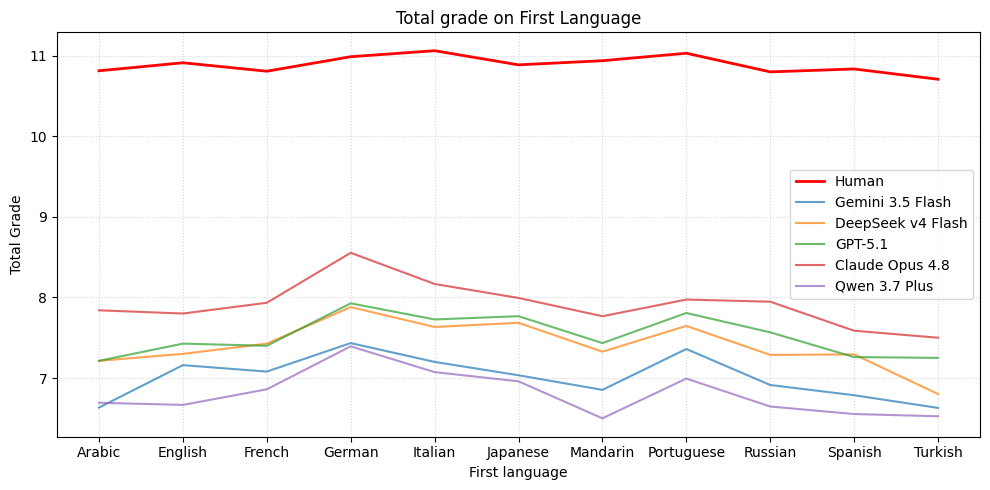

In [ ]:
plot_benchmark(l1_benchmark, 'First Language')

In [ ]:
cefr_benchmark = grouping_table('cefr')
cefr_benchmark

,total_essays,human_avg,gemini_avg,deepseek_avg,gpt5_avg,claude_avg,qwen_avg
cefr,,,,,,,
B1,550,10.659927,6.303636,7.267273,7.380000,7.301818,6.540000
B2,537,10.888939,6.854749,6.720670,6.791434,7.573557,6.437616
C1,525,11.135314,7.925714,8.297143,8.443810,8.931429,7.478095


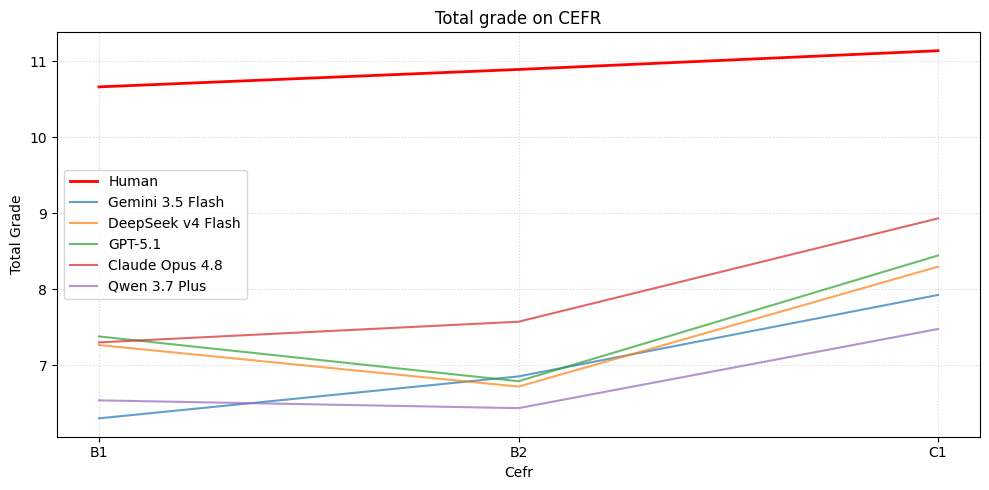

In [ ]:
plot_benchmark(cefr_benchmark, 'CEFR')

In [ ]:
full_scored['wordcount'] = pd.to_numeric(full_scored['wordcount'], errors='coerce')

max_tokens = int(full_scored['wordcount'].max())
bins = np.arange(0, max_tokens + 20, 20)
full_scored['wordcount_bins'] = pd.cut(full_scored['wordcount'], bins=bins)

wordcount_benchmarks = grouping_table('wordcount_bins').dropna()

wordcount_benchmarks

/tmp/ipykernel_1212/2664696260.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  table = full_scored.groupby(column).agg(


,total_essays,human_avg,gemini_avg,deepseek_avg,gpt5_avg,claude_avg,qwen_avg
wordcount_bins,,,,,,,
"(80, 100]",65,10.999385,5.907692,6.615385,7.138462,6.907692,6.369231
"(100, 120]",442,10.863529,6.169683,6.576923,6.640271,7.092760,6.226244
"(120, 140]",262,10.721221,6.667939,6.912214,7.000000,7.484733,6.408397
"(140, 160]",314,10.919618,7.254777,7.697452,7.863057,8.143312,7.035032
"(160, 180]",307,10.996612,7.755700,8.214984,8.345277,8.710098,7.371336
"(180, 200]",138,11.096522,8.144928,8.528986,8.695652,9.144928,7.630435
"(200, 220]",37,10.910270,7.783784,8.135135,7.972973,8.432432,7.081081
"(220, 240]",14,10.671429,7.714286,8.071429,8.285714,8.928571,7.428571
"(240, 260]",12,10.800000,7.166667,7.833333,6.916667,8.083333,6.916667


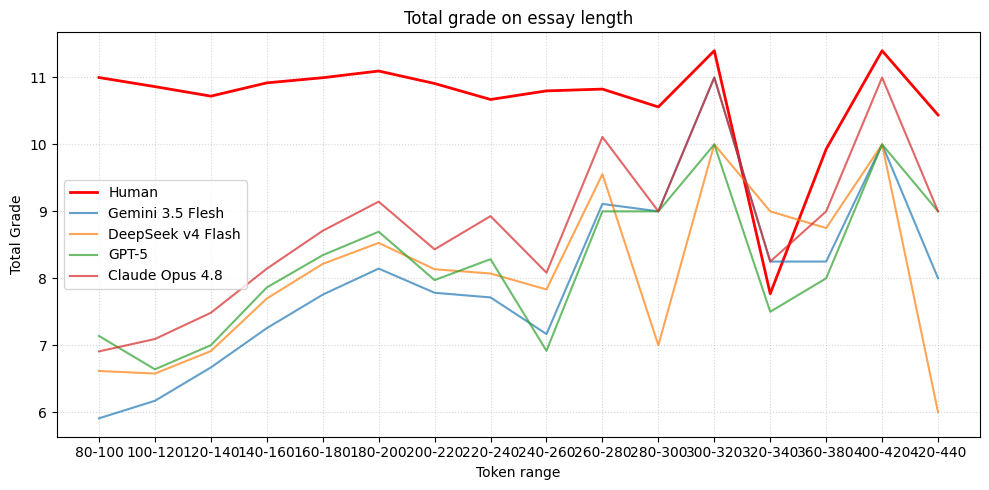

In [ ]:
plt.figure(figsize=(10, 5))

x_labels = [f"{int(b.left)}-{int(b.right)}" for b in wordcount_benchmarks.index]

plt.plot(x_labels, wordcount_benchmarks['human_avg'], label='Human', color='red', linewidth=2)
plt.plot(x_labels, wordcount_benchmarks['gemini_avg'], label='Gemini 3.5 Flesh', alpha=0.7)
plt.plot(x_labels, wordcount_benchmarks['deepseek_avg'], label='DeepSeek v4 Flash', alpha=0.7)
plt.plot(x_labels, wordcount_benchmarks['gpt5_avg'], label='GPT-5', alpha=0.7)
plt.plot(x_labels, wordcount_benchmarks['claude_avg'], label='Claude Opus 4.8', alpha=0.7)
plt.title('Total grade on essay length')
plt.ylabel('Total Grade')
plt.xlabel('Token range')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.5)
plt.tight_layout()

plt.show()

## t-test (Human vs Models with context)

In [ ]:
import pandas as pd
from scipy import stats

models = ['gemini', 'deepseek', 'gpt5', 'claude', 'qwen']
ttest_results = []
human_scores = full_scored['grade (/12)']

for model in models:
    context_scores = full_scored[f"{model}_total"]

    t_stat, p_val = stats.ttest_rel(context_scores, human_scores, nan_policy='omit')

    is_significant = "Significant" if p_val < 0.05 else "Not significant"

    ttest_results.append({
        'Model': model,
        't-statistic': round(t_stat, 3),
        'p-value': round(p_val, 5) if p_val >= 0.00001 else "< 0.00001",
        'Stat. Significant (alpha=0.05)': is_significant
    })

ttest_df = pd.DataFrame(ttest_results)
ttest_df

,Model,t-statistic,p-value,Stat. Significant (alpha=0.05)
0,gemini,-98.869,< 0.00001,Significant
1,deepseek,-76.306,< 0.00001,Significant
2,gpt5,-63.992,< 0.00001,Significant
3,claude,-70.353,< 0.00001,Significant
4,qwen,-108.070,< 0.00001,Significant


Показники т-статистики показють, що кожна модель занижує оцінки, в порівнянні з людськими

In [ ]:
from sklearn.metrics import cohen_kappa_score
import pandas as pd

models = ['gemini', 'deepseek', 'gpt5', 'claude', 'qwen']

qwk_results = {}

for model in models:
    valid_data = full_scored[[f'{model}_total', 'grade (/12)']].dropna()

    y_true = valid_data['grade (/12)'].astype(int)
    y_pred = valid_data[f'{model}_total'].astype(int)

    qwk_score = cohen_kappa_score(y_true, y_pred, weights='quadratic')

    qwk_results[model] = round(qwk_score, 4)

qwk_df = pd.DataFrame(list(qwk_results.items()), columns=['Model', 'Quadratic Weighted Kappa (QWK)'])
qwk_df = qwk_df.sort_values(by='Quadratic Weighted Kappa (QWK)', ascending=False)

print(qwk_df)

      Model  Quadratic Weighted Kappa (QWK)
3    claude                          0.1088
2      gpt5                          0.0918
0    gemini                          0.0673
1  deepseek                          0.0645
4      qwen                          0.0557


## Differential Analysis

In [ ]:
qwen_scored = pd.read_csv('/content/drive/MyDrive/AES_data/efcamdat_qwen_scored.csv')
other_scored = pd.read_csv('/content/drive/MyDrive/AES_data/efcamdat_claude_scored.csv')
full_scored = other_scored.merge(qwen_scored, on = ['writing_id',
                                                    'level',
                                                    'unit',
                                                    'learner_id',
                                                    'nationality',
                                                    'topic_id',
                                                    'topic_text',
                                                    'date',
                                                    'grade',
                                                    'essay_text',
                                                    'wordcount',
                                                    'l1',
                                                    'cefr',
                                                    'cefr_numeric',
                                                    'grade (/12)'], how = 'inner')
full_scored.to_csv('/content/drive/MyDrive/AES_data/efcamdat_full_scored.csv')

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
full_scored = pd.read_csv('/content/drive/MyDrive/AES_data/efcamdat_full_scored.csv')

In [ ]:
model_list = ['gemini', 'deepseek', 'gpt5', 'claude', 'qwen']
for model in model_list:
  full_scored[f'{model}_total_error'] = full_scored[f'{model}_total'] - full_scored['grade (/12)']

In [ ]:
import pandas as pd
import numpy as np

categories = {'human': 'grade (/12)'}
models = ['gemini', 'deepseek', 'gpt5', 'claude', 'qwen']
metrics = ['osa', 'osd', 'csd']
demographics = ['l1', 'cefr', 'wordcount']

row_index = pd.MultiIndex.from_tuples(
    [(cat_name, metric, model) for cat_name in categories.values() for metric in metrics for model in models],
    names=['Label', 'Metric', 'Model']
)

aggregated_table = pd.DataFrame(index=row_index, columns=demographics)

for cat_short, cat_long in categories.items():
    for model in models:

        err_col = f"{model}_total_error"

        for demo in demographics:
            grouped = full_scored.groupby(demo)[err_col]

            osa_val = grouped.apply(lambda x: x.abs().mean()).mean()

            group_signed_errors = grouped.mean()
            osd_val = group_signed_errors.abs().mean()

            total_mean_error = full_scored[err_col].mean()
            csd_val = (group_signed_errors - total_mean_error).abs().mean()

            aggregated_table.at[(cat_long, 'osa', model), demo] = round(osa_val, 3)
            aggregated_table.at[(cat_long, 'osd', model), demo] = round(osd_val, 3)
            aggregated_table.at[(cat_long, 'csd', model), demo] = round(csd_val, 3)

aggregated_table.to_csv('/content/drive/MyDrive/AES_data/differential_analysis_human_efcamdat.csv')


aggregated_table

l1   cefr wordcount
Label       Metric Model                           
grade (/12) osa    gemini     3.93  3.918     3.408
                   deepseek  3.549  3.537     3.104
                   gpt5      3.434  3.428     3.076
                   claude    3.058  3.045     2.568
                   qwen      4.122  4.117      3.77
            osd    gemini     3.88  3.867     3.368
                   deepseek  3.479  3.466     3.041
                   gpt5      3.362  3.356     3.024
                   claude    2.973  2.959     2.501
                   qwen      4.081  4.076     3.747
            csd    gemini    0.158  0.435     0.946
                   deepseek  0.164  0.469     1.009
                   gpt5      0.154  0.496     1.093
                   claude    0.168  0.501      1.01
                   qwen      0.168  0.278     0.753

In [ ]:
!cp differential_analysis_human_efcamdat.csv "/content/drive/MyDrive/AES_data/"

## Heatmap

In [ ]:
import pandas as pd
import numpy as np

models = ['gemini', 'deepseek', 'gpt5', 'claude', 'qwen']

unique_l1 = sorted(full_scored['l1'].dropna().unique())
csd_heatmap_df = pd.DataFrame(index=unique_l1, columns=models)

for model in models:
    err_col = f"{model}_total_error"

    if err_col not in full_scored.columns:
        full_scored[err_col] = full_scored[f'{model}_total'] - full_scored['grade (/12)']

    total_mean_error = full_scored[err_col].mean()
    grouped_errors = full_scored.groupby('l1')[err_col].mean()

    for l1_group in unique_l1:
        if l1_group in grouped_errors.index:
            csd_group_val = grouped_errors[l1_group] - total_mean_error

            csd_heatmap_df.at[l1_group, model] = round(csd_group_val, 3)

csd_heatmap_df

,gemini,deepseek,gpt5,claude,qwen
Arabic,-0.302,-0.127,-0.237,-0.003,-0.038
English,0.125,-0.14,-0.123,-0.142,-0.164
French,0.15,0.092,-0.045,0.096,0.134
German,0.323,0.365,0.302,0.536,0.487
Italian,0.016,0.044,0.027,0.075,0.093
Japanese,0.025,0.271,0.243,0.076,0.154
Mandarin,-0.207,-0.139,-0.142,-0.201,-0.356
Portuguese,0.207,0.088,0.139,-0.088,0.044
Russian,-0.009,-0.04,0.13,0.117,-0.071
Spanish,-0.171,-0.07,-0.213,-0.279,-0.201


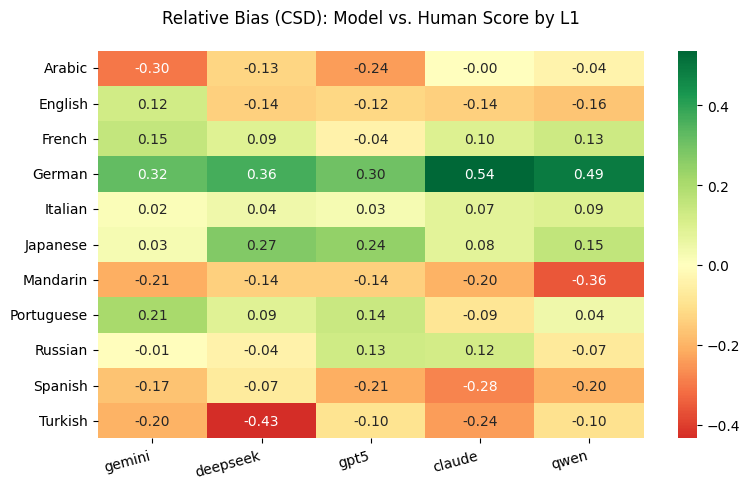

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

bias_deviation = csd_heatmap_df.astype(float)

plt.figure(figsize=(8, 5))
sns.heatmap(bias_deviation, annot=True, cmap='RdYlGn', center=0, fmt=".2f")
plt.title('Relative Bias (CSD): Model vs. Human Score by L1', pad=20)

plt.xticks(rotation=15, ha='right')
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

Було змінено логіку зафарбовування клітинок через використання умовного відхилення замість звичайного, оскільки таке відхилення буде враховувати загальну суворість моделі й оцінюватиме різницю між тим як вона загалом оцінює всіх і відхиленням між людиною (де всі значення до того були занижченими через суворість ллмок)

Формула: $\text{Mean}(S - H)_{\text{Group}} - \text{Total Mean}(S - H)$

тоді як звичайне відхилення

Формула: $\text{Mean}(S - H)_{\text{Group}}$

Низький загальний індекс csd для чинника рідної мови (l1 $\approx$ 0.16) свідчить про те, що на макрорівні мовні метадані не викликають системного зсуву оцінювання. Проте деталізований аналіз на рівні окремих лінгвістичних груп виявляє точкові аномалії: моделі демонструють виражений фаворитизм до носіїв німецької мови та підвищену суворість до носіїв турецької та мандаринської мов. Малий загальний показник csd пояснюється великою кількістю нейтральних мовних груп, які математично нівелюють вплив цих поодиноких екстремумів при загальному усередненні

## Additional Scoring Essays without context

In [ ]:
!pip install -q -U google-generativeai

import google.generativeai as genai
from google.colab import userdata
import time
import pandas as pd
import json

from google.colab import drive
import os
import pandas as pd

drive.mount('/content/drive')


/usr/local/lib/python3.12/dist-packages/google/colab/_import_hooks/_hook_injector.py:55: FutureWarning: 

All support for the `google.generativeai` package has ended. It will no longer be receiving 
updates or bug fixes. Please switch to the `google.genai` package as soon as possible.
See README for more details:

https://github.com/google-gemini/deprecated-generative-ai-python/blob/main/README.md

  loader.exec_module(module)


Mounted at /content/drive


In [ ]:
efcamdat_df = pd.read_csv("/content/drive/MyDrive/AES_data/efcamdat_qwen_nc_scored.csv")
efcamdat_df

,Unnamed: 0,writing_id,level,unit,learner_id,nationality,topic_id,topic_text,date,grade,...,gpt5_total,gemini_total,deepseek_total,claude_total,qwen_total,gemini_total_nc,gpt5_total_nc,claude_total_nc,deepseek_total_nc,qwen_total_nc
0,0,262678,9,2,149073,ps,66,Studying online,2012-09-22 18:52:16.653,97,...,9,7,9,9,8,6,9,9,7.0,8.0
1,1,197509,9,8,154485,eg,72,Writing a blog,2011-11-07 08:58:41.503,84,...,8,6,7,7,7,5,8,8,6.0,7.0
2,2,55820,7,2,14811,sy,50,Planning for the future,2011-07-20 20:34:05.670,87,...,7,6,7,7,7,6,7,8,5.0,6.0
3,3,416073,7,4,89040,sd,52,Writing about a memorable experience,2012-04-14 17:06:44.133,100,...,8,7,8,7,7,6,8,8,7.0,7.0
4,4,874785,7,2,156223,sa,50,Planning for the future,2013-09-30 14:33:09.953,100,...,8,6,8,7,6,5,7,7,6.0,6.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1607,1607,264981,13,5,71612,tr,101,Writing about a disaster relief effort,2011-12-18 14:04:38.950,82,...,8,7,5,7,7,5,7,7,6.0,6.0
1608,1608,328343,13,1,138106,tr,97,Writing a campaign speech,2012-03-15 18:07:43.060,89,...,8,6,4,6,6,4,7,6,5.0,5.0
1609,1609,128116,13,1,62531,tr,97,Writing a campaign speech,2011-08-01 19:45:14.427,96,...,6,5,2,4,4,4,6,4,4.0,4.0
1610,1610,510760,13,5,111116,tr,101,Writing about a disaster relief effort,2012-09-09 03:09:53.097,83,...,6,6,8,8,7,6,6,7,5.0,6.0


### Gemini 3.5 Flash

In [ ]:
from openai import OpenAI
import json

client = OpenAI(
    api_key=userdata.get("OPENROUTER_API_KEY"),
    base_url="https://openrouter.ai/api/v1"
)
MODEL_NAME = "google/gemini-3.5-flash"

SYSTEM_PROMPT = """
You are an expert English language evaluator scoring ESL student essays.
You will receive a batch of essays. Each essay will be clearly separated and labeled with an [ID: ...].

Grade EACH essay with a single TOTAL score on a scale from 0 to 12 points (where 12 is the maximum possible score).

You must output ONLY a valid JSON object where the keys are the Writing IDs, and the values are the integer total scores. Do not include markdown like ```json.
Example output format:
{
  "12345": 9,
  "67890": 7
}
"""

def get_gpt_batch_scores(batch_df):
    user_prompt = "Evaluate the following essays:\n\n"

    for index, row in batch_df.iterrows():
        user_prompt += f"--- [ID: {row['writing_id']}] ---\n"
        user_prompt += f"Essay:\n{row['essay_text']}\n\n"
    try:
        response = client.chat.completions.create(
            model=MODEL_NAME,
            messages=[
                {"role": "system", "content": SYSTEM_PROMPT},
                {"role": "user", "content": user_prompt}
            ],
            response_format={"type": "json_object"},
            temperature=0.0,
            max_completion_tokens=800
        )

        clean_text = response.choices[0].message.content.strip()
        scores_dict = json.loads(clean_text)
        return scores_dict

    except Exception as e:
        print(f"API Error in batch: {e}")
        return None

In [ ]:
import os
import time

BATCH_SIZE = 5
total_rows = len(efcamdat_df)

output_file = "efcamdat_gemini_nc_scored.csv"

output_col = 'gemini_total_nc'

if output_col not in efcamdat_df.columns:
    efcamdat_df[output_col] = None

for i in range(0, total_rows, BATCH_SIZE):
    batch = efcamdat_df.iloc[i : i + BATCH_SIZE]
    writing_ids = batch['writing_id'].tolist()

    if batch[output_col].notna().all():
        print(f"Batch {i//BATCH_SIZE + 1}: IDs {writing_ids} already scored. Skipping.")
        continue

    print(f"Batch {i//BATCH_SIZE + 1}/{total_rows//BATCH_SIZE + 1}: Scoring IDs {writing_ids}...")

    batch_results = None
    for attempt in range(3):
        batch_results = get_gpt_batch_scores(batch)
        if batch_results:
            break
        print(f"  -> Attempt {attempt + 1} failed. Retrying in 5 seconds...")
        time.sleep(5)

    if batch_results:
        for index, row in batch.iterrows():
            w_id = str(row['writing_id'])

            if w_id in batch_results:
                efcamdat_df.at[index, output_col] = batch_results[w_id]
            elif int(w_id) in batch_results:
                efcamdat_df.at[index, output_col] = batch_results[int(w_id)]
            else:
                print(f"  -> Warning: Missing score for ID {w_id} in JSON response.")

        efcamdat_df.to_csv(output_file, index=False)
    else:
        print(f"  -> Critical Error: Batch {i//BATCH_SIZE + 1} failed after 3 attempts.")

    time.sleep(4)

print(f"\nScoring complete! No Context EFCAMDAT dataset saved to {output_file}")

Batch 1/323: Scoring IDs [262678, 197509, 55820, 416073, 874785]...
Batch 2/323: Scoring IDs [488352, 175695, 256389, 377708, 312171]...
Batch 3/323: Scoring IDs [378859, 200173, 151196, 495614, 520257]...
Batch 4/323: Scoring IDs [15582, 418607, 332543, 92294, 524758]...
Batch 5/323: Scoring IDs [398221, 189543, 219410, 116721, 86174]...
Batch 6/323: Scoring IDs [23616, 15579, 444485, 247929, 219405]...
Batch 7/323: Scoring IDs [200808, 45250, 369226, 449653, 537406]...
Batch 8/323: Scoring IDs [299855, 657505, 420436, 1016305, 505304]...
Batch 9/323: Scoring IDs [219392, 348531, 212411, 348765, 9084]...
Batch 10/323: Scoring IDs [530721, 116839, 472872, 104919, 500079]...
Batch 11/323: Scoring IDs [406069, 482222, 251733, 950645, 982343]...
Batch 12/323: Scoring IDs [499658, 197354, 169476, 507296, 72092]...
Batch 13/323: Scoring IDs [112662, 606113, 97312, 235702, 459227]...
Batch 14/323: Scoring IDs [103461, 264284, 887, 310213, 197521]...
Batch 15/323: Scoring IDs [1194960, 203053

In [ ]:
!cp efcamdat_gemini_nc_scored.csv "/content/drive/MyDrive/AES_data/"

### GPT-5.1

In [ ]:
import json
import time
import pandas as pd
from openai import OpenAI
from google.colab import userdata

OPENAI_API_KEY = userdata.get('OPENAI_API_KEY')
client = OpenAI(api_key=OPENAI_API_KEY)

MODEL_NAME = "gpt-5.1"

SYSTEM_PROMPT = """
You are an expert English language evaluator scoring ESL student essays.
You will receive a batch of essays. Each essay will be clearly separated and labeled with an [ID: ...].

Grade EACH essay with a single TOTAL score on a scale from 0 to 12 points (where 12 is the maximum possible score).

You must output ONLY a valid JSON object where the keys are the Writing IDs, and the values are the integer total scores. Do not include markdown like ```json.
Example output format:
{
  "12345": 9,
  "67890": 7
}
"""

def get_gpt_batch_scores(batch_df):
    user_prompt = "Evaluate the following essays:\n\n"

    for index, row in batch_df.iterrows():
        user_prompt += f"--- [ID: {row['writing_id']}] ---\n"
        user_prompt += f"Essay:\n{row['essay_text']}\n\n"
    try:
        response = client.chat.completions.create(
            model=MODEL_NAME,
            messages=[
                {"role": "system", "content": SYSTEM_PROMPT},
                {"role": "user", "content": user_prompt}
            ],
            response_format={"type": "json_object"},
            temperature=0.0,
            max_completion_tokens=800
        )

        clean_text = response.choices[0].message.content.strip()
        scores_dict = json.loads(clean_text)
        return scores_dict

    except Exception as e:
        print(f"API Error in batch: {e}")
        return None


In [ ]:
import os
import time

BATCH_SIZE = 5
total_rows = len(efcamdat_df)

output_file = "efcamdat_gpt5_nc_scored.csv"

output_col = 'gpt5_total_nc'

if output_col not in efcamdat_df.columns:
    efcamdat_df[output_col] = None

for i in range(0, total_rows, BATCH_SIZE):
    batch = efcamdat_df.iloc[i : i + BATCH_SIZE]
    writing_ids = batch['writing_id'].tolist()

    if batch[output_col].notna().all():
        print(f"Batch {i//BATCH_SIZE + 1}: IDs {writing_ids} already scored. Skipping.")
        continue

    print(f"Batch {i//BATCH_SIZE + 1}/{total_rows//BATCH_SIZE + 1}: Scoring IDs {writing_ids}...")

    batch_results = None
    for attempt in range(3):
        batch_results = get_gpt_batch_scores(batch)
        if batch_results:
            break
        print(f"  -> Attempt {attempt + 1} failed. Retrying in 5 seconds...")
        time.sleep(5)

    if batch_results:
        for index, row in batch.iterrows():
            w_id = str(row['writing_id'])

            if w_id in batch_results:
                efcamdat_df.at[index, output_col] = batch_results[w_id]
            elif int(w_id) in batch_results:
                efcamdat_df.at[index, output_col] = batch_results[int(w_id)]
            else:
                print(f"  -> Warning: Missing score for ID {w_id} in JSON response.")

        efcamdat_df.to_csv(output_file, index=False)
    else:
        print(f"  -> Critical Error: Batch {i//BATCH_SIZE + 1} failed after 3 attempts.")

    time.sleep(4)

print(f"\nScoring complete! No Context EFCAMDAT dataset saved to {output_file}")

Batch 1/323: Scoring IDs [262678, 197509, 55820, 416073, 874785]...
Batch 2/323: Scoring IDs [488352, 175695, 256389, 377708, 312171]...
Batch 3/323: Scoring IDs [378859, 200173, 151196, 495614, 520257]...
Batch 4/323: Scoring IDs [15582, 418607, 332543, 92294, 524758]...
Batch 5/323: Scoring IDs [398221, 189543, 219410, 116721, 86174]...
Batch 6/323: Scoring IDs [23616, 15579, 444485, 247929, 219405]...
Batch 7/323: Scoring IDs [200808, 45250, 369226, 449653, 537406]...
Batch 8/323: Scoring IDs [299855, 657505, 420436, 1016305, 505304]...
Batch 9/323: Scoring IDs [219392, 348531, 212411, 348765, 9084]...
Batch 10/323: Scoring IDs [530721, 116839, 472872, 104919, 500079]...
Batch 11/323: Scoring IDs [406069, 482222, 251733, 950645, 982343]...
Batch 12/323: Scoring IDs [499658, 197354, 169476, 507296, 72092]...
Batch 13/323: Scoring IDs [112662, 606113, 97312, 235702, 459227]...
Batch 14/323: Scoring IDs [103461, 264284, 887, 310213, 197521]...
Batch 15/323: Scoring IDs [1194960, 203053

In [ ]:
!cp efcamdat_gpt5_nc_scored.csv "/content/drive/MyDrive/AES_data/"

### Claude Opus 4.8

In [ ]:
from openai import OpenAI
import json

client = OpenAI(
    api_key=userdata.get("OPENROUTER_API_KEY"),
    base_url="https://openrouter.ai/api/v1"
)
MODEL_NAME = "anthropic/claude-opus-4.8"

SYSTEM_PROMPT = """
You are an expert English language evaluator scoring ESL student essays.
You will receive a batch of essays. Each essay will be clearly separated and labeled with an [ID: ...].

Grade EACH essay with a single TOTAL score on a scale from 0 to 12 points (where 12 is the maximum possible score).

You must output ONLY a valid JSON object where the keys are the Writing IDs, and the values are the integer total scores. Do not include markdown like ```json.
Example output format:
{
  "12345": 9,
  "67890": 7
}
"""

def get_gpt_batch_scores(batch_df):
    user_prompt = "Evaluate the following essays:\n\n"

    for index, row in batch_df.iterrows():
        user_prompt += f"--- [ID: {row['writing_id']}] ---\n"
        user_prompt += f"Essay:\n{row['essay_text']}\n\n"
    try:
        response = client.chat.completions.create(
            model=MODEL_NAME,
            messages=[
                {"role": "system", "content": SYSTEM_PROMPT},
                {"role": "user", "content": user_prompt}
            ],
            response_format={"type": "json_object"},
            temperature=0.0,
            max_completion_tokens=800
        )

        clean_text = response.choices[0].message.content.strip()
        scores_dict = json.loads(clean_text)
        return scores_dict

    except Exception as e:
        print(f"API Error in batch: {e}")
        return None

In [ ]:
import os
import time

BATCH_SIZE = 5
total_rows = len(efcamdat_df)
output_file = "efcamdat_claude_nc_scored.csv"

output_col = 'claude_total_nc'
if output_col not in efcamdat_df.columns:
    efcamdat_df[output_col] = None

for i in range(0, total_rows, BATCH_SIZE):
    batch = efcamdat_df.iloc[i : i + BATCH_SIZE]
    writing_ids = batch['writing_id'].tolist()

    if batch[output_col].notna().all():
        print(f"Batch {i//BATCH_SIZE + 1}: IDs {writing_ids} already scored. Skipping.")
        continue

    print(f"Batch {i//BATCH_SIZE + 1}/{total_rows//BATCH_SIZE + 1}: Scoring IDs {writing_ids}...")

    batch_results = None
    for attempt in range(3):
        batch_results = get_gpt_batch_scores(batch)
        if batch_results:
            break
        print(f"  -> Attempt {attempt + 1} failed. Retrying in 5 seconds...")
        time.sleep(5)

    if batch_results:
        for index, row in batch.iterrows():
            w_id = str(row['writing_id'])

            if w_id in batch_results:
                efcamdat_df.at[index, output_col] = batch_results[w_id]
            elif int(w_id) in batch_results:
                efcamdat_df.at[index, output_col] = batch_results[int(w_id)]
            else:
                print(f"  -> Warning: Missing score for ID {w_id} in JSON response.")

        efcamdat_df.to_csv(output_file, index=False)
    else:
        print(f"  -> Critical Error: Batch {i//BATCH_SIZE + 1} failed after 3 attempts.")

    time.sleep(4)

print(f"\nScoring complete! EFCAMDAT dataset saved to {output_file}")

Batch 1/323: Scoring IDs [262678, 197509, 55820, 416073, 874785]...
Batch 2/323: Scoring IDs [488352, 175695, 256389, 377708, 312171]...
Batch 3/323: Scoring IDs [378859, 200173, 151196, 495614, 520257]...
Batch 4/323: Scoring IDs [15582, 418607, 332543, 92294, 524758]...
Batch 5/323: Scoring IDs [398221, 189543, 219410, 116721, 86174]...
Batch 6/323: Scoring IDs [23616, 15579, 444485, 247929, 219405]...
Batch 7/323: Scoring IDs [200808, 45250, 369226, 449653, 537406]...
Batch 8/323: Scoring IDs [299855, 657505, 420436, 1016305, 505304]...
Batch 9/323: Scoring IDs [219392, 348531, 212411, 348765, 9084]...
Batch 10/323: Scoring IDs [530721, 116839, 472872, 104919, 500079]...
Batch 11/323: Scoring IDs [406069, 482222, 251733, 950645, 982343]...
Batch 12/323: Scoring IDs [499658, 197354, 169476, 507296, 72092]...
Batch 13/323: Scoring IDs [112662, 606113, 97312, 235702, 459227]...
Batch 14/323: Scoring IDs [103461, 264284, 887, 310213, 197521]...
Batch 15/323: Scoring IDs [1194960, 203053

In [ ]:
!cp efcamdat_claude_nc_scored.csv "/content/drive/MyDrive/AES_data/"

### DeepSeek v4 Flash

In [ ]:
from openai import OpenAI
import json

client = OpenAI(
    api_key=userdata.get("OPENROUTER_API_KEY"),
    base_url="https://openrouter.ai/api/v1"
)
MODEL_NAME = "deepseek/deepseek-v4-flash"

SYSTEM_PROMPT = """
You are an expert English language evaluator scoring ESL student essays.
You will receive a batch of essays. Each essay will be clearly separated and labeled with an [ID: ...].

Grade EACH essay with a single TOTAL score on a scale from 0 to 12 points (where 12 is the maximum possible score).

You must output ONLY a valid JSON object where the keys are the Writing IDs, and the values are the integer total scores. Do not include markdown like ```json.
Example output format:
{
  "12345": 9,
  "67890": 7
}
"""

def get_gpt_batch_scores(batch_df):
    user_prompt = "Evaluate the following essays:\n\n"

    for index, row in batch_df.iterrows():
        user_prompt += f"--- [ID: {row['writing_id']}] ---\n"
        user_prompt += f"Essay:\n{row['essay_text']}\n\n"
    try:
        response = client.chat.completions.create(
            model=MODEL_NAME,
            messages=[
                {"role": "system", "content": SYSTEM_PROMPT},
                {"role": "user", "content": user_prompt}
            ],
            response_format={"type": "json_object"},
            temperature=0.0,
            max_completion_tokens=800
        )

        clean_text = response.choices[0].message.content.strip()
        scores_dict = json.loads(clean_text)
        return scores_dict

    except Exception as e:
        print(f"API Error in batch: {e}")
        return None

In [ ]:
import os
import time

BATCH_SIZE = 5
total_rows = len(efcamdat_df)
output_file = "efcamdat_deepseek_nc_scored.csv"

output_col = 'deepseek_total_nc'
if output_col not in efcamdat_df.columns:
    efcamdat_df[output_col] = None

for i in range(0, total_rows, BATCH_SIZE):
    batch = efcamdat_df.iloc[i : i + BATCH_SIZE]
    writing_ids = batch['writing_id'].tolist()

    if batch[output_col].notna().all():
        print(f"Batch {i//BATCH_SIZE + 1}: IDs {writing_ids} already scored. Skipping.")
        continue

    print(f"Batch {i//BATCH_SIZE + 1}/{total_rows//BATCH_SIZE + 1}: Scoring IDs {writing_ids}...")

    batch_results = None
    for attempt in range(3):
        batch_results = get_gpt_batch_scores(batch)
        if batch_results:
            break
        print(f"  -> Attempt {attempt + 1} failed. Retrying in 5 seconds...")
        time.sleep(5)

    if batch_results:
        for index, row in batch.iterrows():
            w_id = str(row['writing_id'])

            if w_id in batch_results:
                efcamdat_df.at[index, output_col] = batch_results[w_id]
            elif int(w_id) in batch_results:
                efcamdat_df.at[index, output_col] = batch_results[int(w_id)]
            else:
                print(f"  -> Warning: Missing score for ID {w_id} in JSON response.")

        efcamdat_df.to_csv(output_file, index=False)
    else:
        print(f"  -> Critical Error: Batch {i//BATCH_SIZE + 1} failed after 3 attempts.")

    time.sleep(4)

print(f"\nScoring complete! EFCAMDAT dataset saved to {output_file}")

Batch 1/323: Scoring IDs [262678, 197509, 55820, 416073, 874785]...
Batch 2/323: Scoring IDs [488352, 175695, 256389, 377708, 312171]...
Batch 3/323: Scoring IDs [378859, 200173, 151196, 495614, 520257]...
Batch 4/323: Scoring IDs [15582, 418607, 332543, 92294, 524758]...
API Error in batch: 'NoneType' object has no attribute 'strip'
  -> Attempt 1 failed. Retrying in 5 seconds...
Batch 5/323: Scoring IDs [398221, 189543, 219410, 116721, 86174]...
API Error in batch: 'NoneType' object has no attribute 'strip'
  -> Attempt 1 failed. Retrying in 5 seconds...
Batch 6/323: Scoring IDs [23616, 15579, 444485, 247929, 219405]...
Batch 7/323: Scoring IDs [200808, 45250, 369226, 449653, 537406]...
Batch 8/323: Scoring IDs [299855, 657505, 420436, 1016305, 505304]...
Batch 9/323: Scoring IDs [219392, 348531, 212411, 348765, 9084]...
API Error in batch: 'NoneType' object has no attribute 'strip'
  -> Attempt 1 failed. Retrying in 5 seconds...
Batch 10/323: Scoring IDs [530721, 116839, 472872, 104

In [ ]:
!cp efcamdat_deepseek_nc_scored.csv "/content/drive/MyDrive/AES_data/"

### Qwen 3.7 Pro

In [ ]:
from openai import OpenAI
import json

client = OpenAI(
    api_key=userdata.get("OPENROUTER_API_KEY"),
    base_url="https://openrouter.ai/api/v1"
)
MODEL_NAME = "qwen/qwen3.7-plus"

SYSTEM_PROMPT = """
You are an expert English language evaluator scoring ESL student essays.
You will receive a batch of essays. Each essay will be clearly separated and labeled with an [ID: ...].

Grade EACH essay with a single TOTAL score on a scale from 0 to 12 points (where 12 is the maximum possible score).

You must output ONLY a valid JSON object where the keys are the Writing IDs, and the values are the integer total scores. Do not include markdown like ```json.
Example output format:
{
  "12345": 9,
  "67890": 7
}
"""

def get_gpt_batch_scores(batch_df):
    user_prompt = "Evaluate the following essays:\n\n"

    for index, row in batch_df.iterrows():
        user_prompt += f"--- [ID: {row['writing_id']}] ---\n"
        user_prompt += f"Essay:\n{row['essay_text']}\n\n"
    try:
        response = client.chat.completions.create(
            model=MODEL_NAME,
            messages=[
                {"role": "system", "content": SYSTEM_PROMPT},
                {"role": "user", "content": user_prompt}
            ],
            response_format={"type": "json_object"},
            temperature=0.0,
            max_completion_tokens=800
        )

        clean_text = response.choices[0].message.content.strip()
        scores_dict = json.loads(clean_text)
        return scores_dict

    except Exception as e:
        print(f"API Error in batch: {e}")
        return None

In [ ]:
import os
import time

BATCH_SIZE = 5
total_rows = len(efcamdat_df)
output_file = "efcamdat_qwen_nc_scored.csv"

output_col = 'qwen_total_nc'
if output_col not in efcamdat_df.columns:
    efcamdat_df[output_col] = None

for i in range(0, total_rows, BATCH_SIZE):
    batch = efcamdat_df.iloc[i : i + BATCH_SIZE]
    writing_ids = batch['writing_id'].tolist()

    if batch[output_col].notna().all():
        print(f"Batch {i//BATCH_SIZE + 1}: IDs {writing_ids} already scored. Skipping.")
        continue

    print(f"Batch {i//BATCH_SIZE + 1}/{total_rows//BATCH_SIZE + 1}: Scoring IDs {writing_ids}...")

    batch_results = None
    for attempt in range(3):
        batch_results = get_gpt_batch_scores(batch)
        if batch_results:
            break
        print(f"  -> Attempt {attempt + 1} failed. Retrying in 5 seconds...")
        time.sleep(5)

    if batch_results:
        for index, row in batch.iterrows():
            w_id = str(row['writing_id'])

            if w_id in batch_results:
                efcamdat_df.at[index, output_col] = batch_results[w_id]
            elif int(w_id) in batch_results:
                efcamdat_df.at[index, output_col] = batch_results[int(w_id)]
            else:
                print(f"  -> Warning: Missing score for ID {w_id} in JSON response.")

        efcamdat_df.to_csv(output_file, index=False)
    else:
        print(f"  -> Critical Error: Batch {i//BATCH_SIZE + 1} failed after 3 attempts.")

    time.sleep(4)

print(f"\nScoring complete! EFCAMDAT dataset saved to {output_file}")

Batch 1: IDs [262678, 197509, 55820, 416073, 874785] already scored. Skipping.
Batch 2: IDs [488352, 175695, 256389, 377708, 312171] already scored. Skipping.
Batch 3: IDs [378859, 200173, 151196, 495614, 520257] already scored. Skipping.
Batch 4: IDs [15582, 418607, 332543, 92294, 524758] already scored. Skipping.
Batch 5: IDs [398221, 189543, 219410, 116721, 86174] already scored. Skipping.
Batch 6: IDs [23616, 15579, 444485, 247929, 219405] already scored. Skipping.
Batch 7: IDs [200808, 45250, 369226, 449653, 537406] already scored. Skipping.
Batch 8: IDs [299855, 657505, 420436, 1016305, 505304] already scored. Skipping.
Batch 9: IDs [219392, 348531, 212411, 348765, 9084] already scored. Skipping.
Batch 10: IDs [530721, 116839, 472872, 104919, 500079] already scored. Skipping.
Batch 11: IDs [406069, 482222, 251733, 950645, 982343] already scored. Skipping.
Batch 12: IDs [499658, 197354, 169476, 507296, 72092] already scored. Skipping.
Batch 13: IDs [112662, 606113, 97312, 235702, 

In [ ]:
!cp efcamdat_qwen_nc_scored.csv "/content/drive/MyDrive/AES_data/"

### Analysis

In [ ]:
!pip install -q -U google-generativeai

import google.generativeai as genai
from google.colab import userdata
import time
import pandas as pd
import json
import numpy as np

from google.colab import drive
import os

drive.mount('/content/drive')


/usr/local/lib/python3.12/dist-packages/google/colab/_import_hooks/_hook_injector.py:55: FutureWarning: 

All support for the `google.generativeai` package has ended. It will no longer be receiving 
updates or bug fixes. Please switch to the `google.genai` package as soon as possible.
See README for more details:

https://github.com/google-gemini/deprecated-generative-ai-python/blob/main/README.md

  loader.exec_module(module)


Mounted at /content/drive


In [ ]:
efcamdat_df = pd.read_csv("/content/drive/MyDrive/AES_data/efcamdat_qwen_nc_scored.csv")
efcamdat_df

,Unnamed: 0,writing_id,level,unit,learner_id,nationality,topic_id,topic_text,date,grade,...,gpt5_total,gemini_total,deepseek_total,claude_total,qwen_total,gemini_total_nc,gpt5_total_nc,claude_total_nc,deepseek_total_nc,qwen_total_nc
0,0,262678,9,2,149073,ps,66,Studying online,2012-09-22 18:52:16.653,97,...,9,7,9,9,8,6,9,9,7.0,8.0
1,1,197509,9,8,154485,eg,72,Writing a blog,2011-11-07 08:58:41.503,84,...,8,6,7,7,7,5,8,8,6.0,7.0
2,2,55820,7,2,14811,sy,50,Planning for the future,2011-07-20 20:34:05.670,87,...,7,6,7,7,7,6,7,8,5.0,6.0
3,3,416073,7,4,89040,sd,52,Writing about a memorable experience,2012-04-14 17:06:44.133,100,...,8,7,8,7,7,6,8,8,7.0,7.0
4,4,874785,7,2,156223,sa,50,Planning for the future,2013-09-30 14:33:09.953,100,...,8,6,8,7,6,5,7,7,6.0,6.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1607,1607,264981,13,5,71612,tr,101,Writing about a disaster relief effort,2011-12-18 14:04:38.950,82,...,8,7,5,7,7,5,7,7,6.0,6.0
1608,1608,328343,13,1,138106,tr,97,Writing a campaign speech,2012-03-15 18:07:43.060,89,...,8,6,4,6,6,4,7,6,5.0,5.0
1609,1609,128116,13,1,62531,tr,97,Writing a campaign speech,2011-08-01 19:45:14.427,96,...,6,5,2,4,4,4,6,4,4.0,4.0
1610,1610,510760,13,5,111116,tr,101,Writing about a disaster relief effort,2012-09-09 03:09:53.097,83,...,6,6,8,8,7,6,6,7,5.0,6.0


#### Vizes

In [ ]:
def grouping_table(column):
  table = efcamdat_df.groupby(column).agg(
    total_essays=('writing_id', 'count'),
    human_avg=('grade (/12)', 'mean'),
    gemini_avg=('gemini_total_nc', 'mean'),
    deepseek_avg=('deepseek_total_nc', 'mean'),
    gpt5_avg=('gpt5_total_nc', 'mean'),
    claude_avg=('claude_total_nc', 'mean'),
    qwen_avg=('qwen_total_nc', 'mean')
    )
  return table

In [ ]:
import matplotlib.pyplot as plt

def plot_benchmark(df, title):
  plt.figure(figsize=(10, 5))

  df = df.drop(columns=['total_essays'])
  plt.plot(df['human_avg'], label='Human', color='red', linewidth=2)
  plt.plot(df['gemini_avg'], label='Gemini 3.5 Flash', alpha=0.7)
  plt.plot(df['deepseek_avg'], label='DeepSeek v4 Flash', alpha=0.7)
  plt.plot(df['gpt5_avg'], label='GPT-5.1', alpha=0.7)
  plt.plot(df['claude_avg'], label='Claude Opus 4.8', alpha=0.7)
  plt.plot(df['qwen_avg'], label='Qwen 3.7 Plus', alpha=0.7)
  plt.title(f'Total grade on {title}')
  plt.ylabel('Total Grade')
  plt.xlabel(title.capitalize())
  plt.legend()
  plt.grid(True, linestyle=':', alpha=0.5)
  plt.tight_layout()

  plt.show()

In [ ]:
l1_benchmark = grouping_table('l1')
l1_benchmark

,total_essays,human_avg,gemini_avg,deepseek_avg,gpt5_avg,claude_avg,qwen_avg
l1,,,,,,,
Arabic,150,10.811200,5.660000,6.240000,6.606667,7.573333,6.413333
English,150,10.910400,5.960000,6.446667,6.933333,7.526667,6.513333
French,150,10.805600,5.920000,6.386207,6.613333,7.793333,6.600000
German,150,10.985600,6.280000,6.693333,7.273333,8.213333,7.053333
Italian,150,11.060000,6.100000,6.653333,7.226667,7.973333,6.740000
Japanese,146,10.884658,5.746575,6.573529,6.835616,7.732877,6.650685
Mandarin,150,10.936000,5.620000,6.180000,6.686667,7.480000,6.253333
Portuguese,150,11.028800,6.173333,6.593333,7.180000,7.786667,6.720000
Russian,150,10.797600,5.733333,6.286667,6.773333,7.620000,6.466667


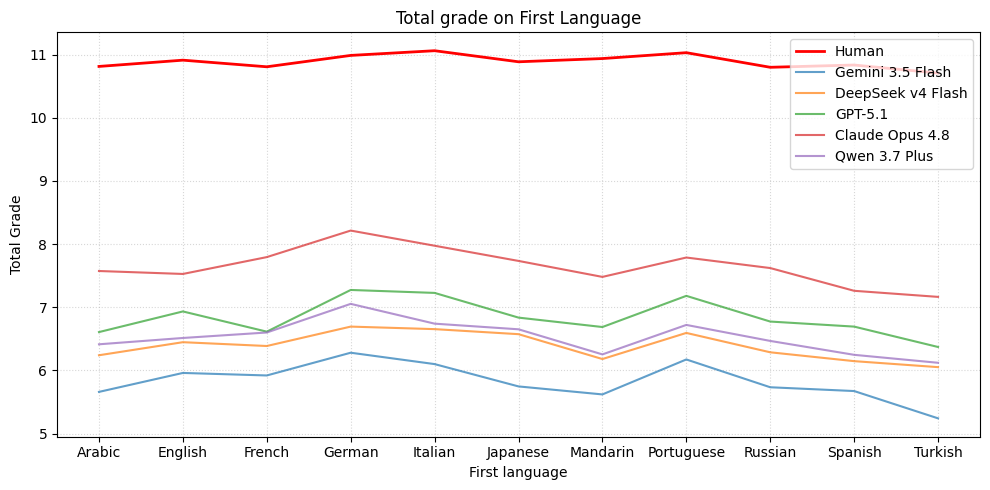

In [ ]:
plot_benchmark(l1_benchmark, 'First Language')

In [ ]:
cefr_benchmark = grouping_table('cefr')
cefr_benchmark

,total_essays,human_avg,gemini_avg,deepseek_avg,gpt5_avg,claude_avg,qwen_avg
cefr,,,,,,,
B1,550,10.659927,5.652727,6.658182,6.880000,7.325455,6.509091
B2,537,10.888939,5.363128,5.308271,5.921788,7.294227,6.102421
C1,525,11.135314,6.525714,7.227184,7.754286,8.377143,7.000000


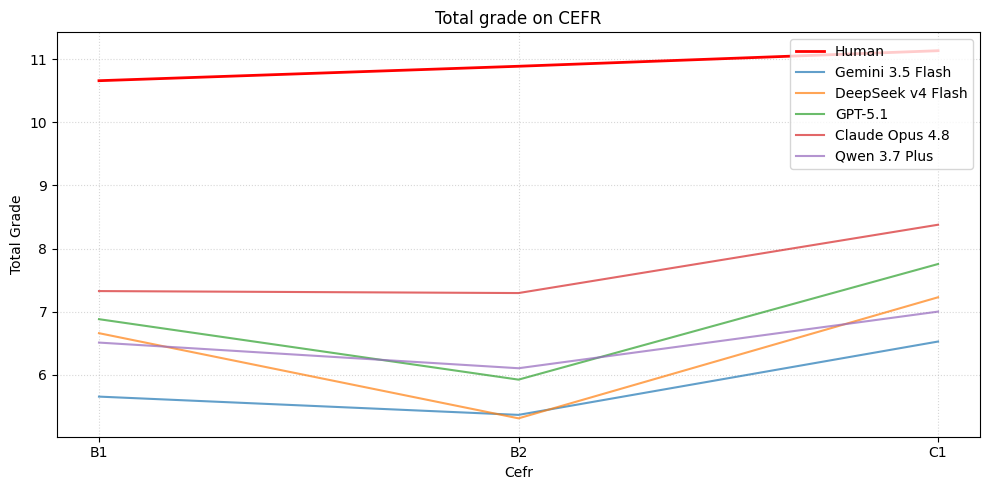

In [ ]:
plot_benchmark(cefr_benchmark, 'CEFR')

In [ ]:

efcamdat_df['wordcount'] = pd.to_numeric(efcamdat_df['wordcount'], errors='coerce')

max_tokens = int(efcamdat_df['wordcount'].max())
bins = np.arange(0, max_tokens + 20, 20)
efcamdat_df['wordcount_bins'] = pd.cut(efcamdat_df['wordcount'], bins=bins)

wordcount_benchmarks = grouping_table('wordcount_bins').dropna()

wordcount_benchmarks

/tmp/ipykernel_1410/3575545451.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  table = efcamdat_df.groupby(column).agg(


,total_essays,human_avg,gemini_avg,deepseek_avg,gpt5_avg,claude_avg,qwen_avg
wordcount_bins,,,,,,,
"(80, 100]",65,10.999385,4.953846,5.907692,6.353846,6.830769,6.338462
"(100, 120]",442,10.863529,5.070136,5.495455,5.907240,6.825792,6.013575
"(120, 140]",262,10.721221,5.404580,5.784615,6.225191,7.183206,6.057252
"(140, 160]",314,10.919618,6.041401,6.593548,7.121019,7.961783,6.726115
"(160, 180]",307,10.996612,6.560261,7.280528,7.824104,8.433225,7.087948
"(180, 200]",138,11.096522,6.905797,7.518519,8.086957,8.688406,7.268116
"(200, 220]",37,10.910270,6.594595,7.243243,7.216216,8.216216,6.729730
"(220, 240]",14,10.671429,6.428571,7.428571,7.428571,8.357143,7.142857
"(240, 260]",12,10.800000,6.416667,7.083333,6.500000,7.833333,6.333333


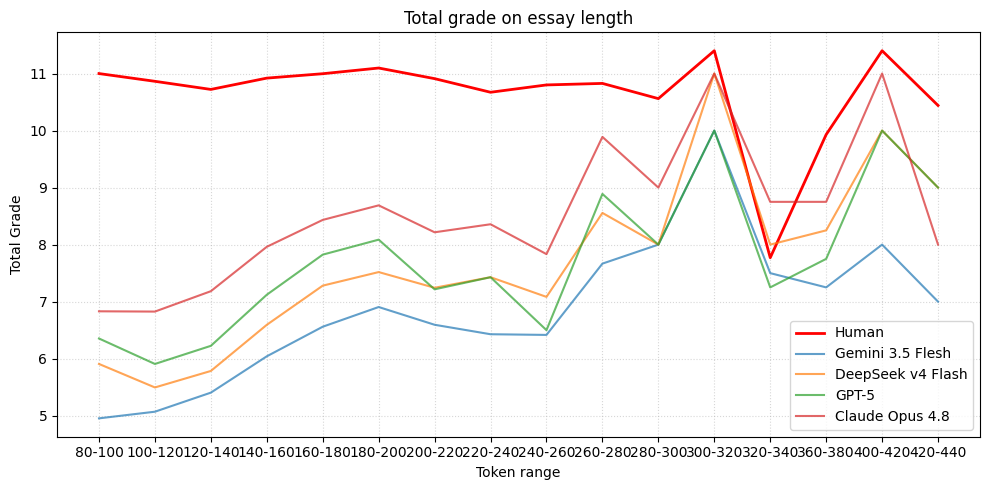

In [ ]:
plt.figure(figsize=(10, 5))

x_labels = [f"{int(b.left)}-{int(b.right)}" for b in wordcount_benchmarks.index]

plt.plot(x_labels, wordcount_benchmarks['human_avg'], label='Human', color='red', linewidth=2)
plt.plot(x_labels, wordcount_benchmarks['gemini_avg'], label='Gemini 3.5 Flesh', alpha=0.7)
plt.plot(x_labels, wordcount_benchmarks['deepseek_avg'], label='DeepSeek v4 Flash', alpha=0.7)
plt.plot(x_labels, wordcount_benchmarks['gpt5_avg'], label='GPT-5', alpha=0.7)
plt.plot(x_labels, wordcount_benchmarks['claude_avg'], label='Claude Opus 4.8', alpha=0.7)
plt.title('Total grade on essay length')
plt.ylabel('Total Grade')
plt.xlabel('Token range')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.5)
plt.tight_layout()

plt.show()

#### t-test (Models with context vs Models without context)

In [ ]:
import pandas as pd
from scipy import stats

models = ['gemini', 'deepseek', 'gpt5', 'claude', 'qwen']
ttest_results = []

for model in models:
    context_scores = efcamdat_df[f"{model}_total"].astype(float)
    no_context_scores = efcamdat_df[f"{model}_total_nc"].astype(float)

    #  (Paired T-test)
    t_stat, p_val = stats.ttest_rel(context_scores, no_context_scores, nan_policy='omit')

    is_significant = "Yes 🚨" if p_val < 0.05 else "No ✅"

    mean_diff = (context_scores - no_context_scores).mean()

    ttest_results.append({
        'Model': model.upper(),
        'Mean Diff (Context - No Context)': round(mean_diff, 3),
        't-statistic': round(t_stat, 3),
        'p-value': round(p_val, 5) if p_val >= 0.00001 else "< 0.00001",
        'Stat. Significant (p < 0.05)': is_significant
    })

ttest_df = pd.DataFrame(ttest_results)
display(ttest_df)

,Model,Mean Diff (Context - No Context),t-statistic,p-value,Stat. Significant (p < 0.05)
0,GEMINI,1.175,57.332,< 0.00001,Yes 🚨
1,DEEPSEEK,1.025,27.047,< 0.00001,Yes 🚨
2,GPT5,0.685,31.755,< 0.00001,Yes 🚨
3,CLAUDE,0.266,14.372,< 0.00001,Yes 🚨
4,QWEN,0.278,14.950,< 0.00001,Yes 🚨


Показники т-статистики показють, що кожна модель занижує оцінки, в порівнянні з людськими

#### Differential Analysis

In [ ]:
import pandas as pd
import numpy as np

models = ['gemini', 'deepseek', 'gpt5', 'claude', 'qwen']
metrics = ['osa', 'osd', 'csd']
demographics = ['l1', 'cefr', 'wordcount']

for model in models:
    efcamdat_df[f'{model}_nc_diff'] = efcamdat_df[f'{model}_total'].astype(float) - efcamdat_df[f'{model}_total_nc'].astype(float)

categories = {'AI_Internal': 'Context vs No Context'}

row_index = pd.MultiIndex.from_tuples(
    [(cat_name, metric, model) for cat_name in categories.values() for metric in metrics for model in models],
    names=['Label', 'Metric', 'Model']
)

aggregated_table = pd.DataFrame(index=row_index, columns=demographics)

for cat_short, cat_long in categories.items():
    for model in models:

        err_col = f"{model}_nc_diff"

        for demo in demographics:
            data = efcamdat_df[[demo, err_col]].dropna()
            grouped = data.groupby(demo)[err_col]

            # OSA: Overall Subgroup Absolute deviation
            osa_val = grouped.apply(lambda x: x.abs().mean()).mean()

            # OSD: Overall Subgroup Deviation
            group_signed_errors = grouped.mean()
            osd_val = group_signed_errors.abs().mean()

            # CSD: Conditional Subgroup Deviation
            total_mean_error = efcamdat_df[err_col].dropna().mean()
            csd_val = (group_signed_errors - total_mean_error).abs().mean()

            aggregated_table.at[(cat_long, 'osa', model), demo] = round(osa_val, 3)
            aggregated_table.at[(cat_long, 'osd', model), demo] = round(osd_val, 3)
            aggregated_table.at[(cat_long, 'csd', model), demo] = round(csd_val, 3)

aggregated_table.to_csv('/content/drive/MyDrive/AES_data/differential_analysis_context_nocontext_efcamdat.csv')
display(aggregated_table)

l1   cefr wordcount
Label                 Metric Model                           
Context vs No Context osa    gemini    1.206  1.206     1.215
                             deepseek  1.407  1.414     1.375
                             gpt5       0.81  0.809      0.78
                             claude    0.504  0.505     0.483
                             qwen        0.5  0.502     0.492
                      osd    gemini     1.18  1.181     1.196
                             deepseek   1.02   1.03     1.109
                             gpt5      0.689  0.686      0.67
                             claude    0.267  0.286     0.338
                             qwen      0.281  0.281     0.364
                      csd    gemini    0.073  0.355     0.299
                             deepseek  0.098  0.283     0.614
                             gpt5      0.125  0.125     0.364
                             claude    0.053  0.197     0.279
                             qwen      0.053  0.168     0.297

In [ ]:
!cp differential_analysis_context_nocontext_efcamdat.csv "/content/drive/MyDrive/AES_data/"

cp: cannot stat 'differential_analysis_context_nocontext_efcamdat.csv': No such file or directory


## Heatmap

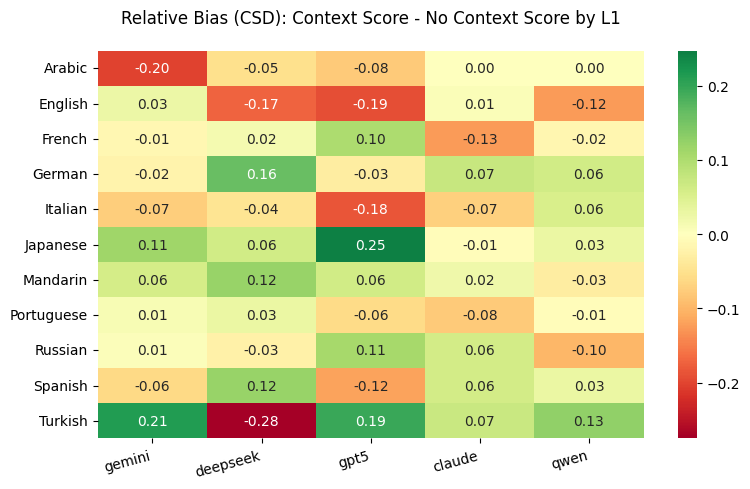

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# Assuming 'models' and 'efcamdat_df' are already defined
models = ['gemini', 'deepseek', 'gpt5', 'claude', 'qwen']

unique_l1 = sorted(efcamdat_df['l1'].dropna().unique())

csd_nc_heatmap_df = pd.DataFrame(index=unique_l1, columns=models)

for model in models:
    err_col = f"{model}_nc_diff"
    if err_col not in efcamdat_df.columns:
        efcamdat_df[err_col] = efcamdat_df[f'{model}_total'].astype(float) - efcamdat_df[f'{model}_total_nc'].astype(float)

    total_mean_error = efcamdat_df[err_col].dropna().mean()

    grouped_errors = efcamdat_df.groupby('l1')[err_col].mean()

    for l1_group in unique_l1:
        if l1_group in grouped_errors.index:

            csd_group_val = grouped_errors[l1_group] - total_mean_error
            csd_nc_heatmap_df.at[l1_group, model] = round(csd_group_val, 3)

bias_deviation_nc = csd_nc_heatmap_df.astype(float)

plt.figure(figsize=(8, 5))
sns.heatmap(bias_deviation_nc, annot=True, cmap='RdYlGn', center=0, fmt=".2f")

plt.title('Relative Bias (CSD): Context Score - No Context Score by L1', pad=20)

plt.xticks(rotation=15, ha='right')
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()